# Milestone 4 : Fiabiliser la solution et analyser les gains

## Section 0 : Ce que nous faisons ici

Aux milestones 1, 2 et 3, nous avons préparé les données, mesuré la situation actuelle,
puis construit le moteur de consolidation (trois versions : libre, intermédiaire, stricte).
Ce quatrième milestone a deux buts :

1. **fiabiliser** : prouver que le moteur est correct, par une suite de tests organisée
   en six familles ;
2. **analyser les gains** : montrer, chiffres à l'appui, ce que le client gagne, où se
   concentre l'économie, et comparer le réalisé à notre potentiel estimé au milestone 2.

Nous écrivons tout en "nous", en français simple. Après chaque résultat, une cellule
"Notre constat :" dit ce que nous en retenons. Les montants sont au format 74 908,28 €,
les pourcentages au format 41,8 %.

**Une seule source de vérité.** Nous ne recopions aucune fonction du milestone 3. La
cellule suivante charge le moteur en exécutant les cellules de code du notebook
milestone3.ipynb sans afficher leurs sorties : ainsi nous testons exactement le code que
nous avons livré, et toute correction du moteur se fait à un seul endroit.

In [1]:
# Nous chargeons le moteur du milestone 3 en executant ses cellules de code, sans afficher
# leurs sorties (figures et impressions neutralisees) ni reecrire ses fichiers : une seule
# source de verite. Neutraliser to_csv evite que ce chargement n'ecrase les sorties du milestone 3.
import json, io, contextlib, warnings
import pandas as pd
import matplotlib.pyplot as plt

_vraie_show = plt.show
_vrai_tocsv = pd.DataFrame.to_csv
plt.show = lambda *a, **k: None              # on n'affiche pas les figures du milestone 3
pd.DataFrame.to_csv = lambda self, *a, **k: None  # on ne reecrit pas les fichiers du milestone 3
_ns = {"display": lambda *a, **k: None}      # on neutralise display()
with open("milestone3.ipynb", encoding="utf-8") as f:
    _nb = json.load(f)
try:
    with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for _c in _nb["cells"]:
            if _c["cell_type"] == "code":
                exec("".join(_c["source"]), _ns)
finally:
    plt.show = _vraie_show                    # on rend l'affichage a nos propres figures
    pd.DataFrame.to_csv = _vrai_tocsv         # on rend to_csv a nos propres exports
plt.close("all")
globals().update({k: v for k, v in _ns.items() if not k.startswith("__") and k != "display"})

# Nous verifions que le chargement prend bien la version a jour du milestone 3 :
# le calendrier commence le lundi 02/11 (7 jours avant le premier besoin du 09/11), et la
# version stricte est la version recommandee par defaut.
assert PREMIER_JOUR_LIVRAISON == "2026-11-02", "Le milestone 3 charge n'a pas le calendrier du 02/11."
assert MODE_PROFIL == "strict", "Le milestone 3 charge n'a pas la version stricte par defaut."
assert len(jours_ouvres) == 35, "Le calendrier charge ne compte pas 35 jours ouvres."
assert str(d0.date()) == "2026-11-02" and str(d1.date()) == "2026-12-18", "Bornes de l'horizon inattendues."

_eur = lambda x: f"{x:,.2f}".replace(",", " ").replace(".", ",") + " €"
print("Moteur du milestone 3 charge.")
print("Perimetre :", len(opt), "lignes optimisees,", opt.groupby(["supplier_id", "plant"]).ngroups, "couples.")
print("Version du milestone 3 :", MODE_PROFIL, "(recommandee par defaut) ; calendrier de",
      len(jours_ouvres), "jours ouvres du", d0.date(), "au", d1.date(), ".")
print("Baseline avec H20 :", _eur(baseline_H20), "| cout de la version retenue (stricte) :", _eur(cout_final), ".")


Moteur du milestone 3 charge.
Perimetre : 4252 lignes optimisees, 171 couples.
Version du milestone 3 : strict (recommandee par defaut) ; calendrier de 35 jours ouvres du 2026-11-02 au 2026-12-18 .
Baseline avec H20 : 143 320,74 € | cout de la version retenue (stricte) : 82 110,82 € .


**Notre constat :** le moteur est chargé, dans sa version à jour : le calendrier commence le
lundi 02/11 (7 jours avant le premier besoin du 09/11) et la version stricte est recommandée
par défaut. Nous disposons de toutes ses fonctions (`prix_camion`, `evaluer_profil`,
`lancer_moteur`, `valider`, etc.) et de ses données (les 171 couples, les 166 profils, les
baselines). Nous travaillons désormais sur ce moteur, sans en recopier une ligne.

## Section 1 : Notre cadre de tests

Pour que le rendu soit lisible, nous posons d'abord trois petits outils :

- un format d'affichage des montants (74 908,28 €) et des pourcentages (41,8 %) ;
- une fonction `tester(...)` par laquelle **chaque test** passe. Elle enregistre le nom
  du test, sa famille, ce qu'il vérifie, pourquoi nous le testons, son résultat (OK ou
  ÉCHEC) et, en cas d'échec, le détail ;
- un registre `RESULTATS` qui collecte tous les tests pour le tableau final.

Un test **ne s'arrête jamais au premier échec** : une exception est rattrapée et comptée
comme un échec, et nous passons au test suivant. Nous voulons voir tous les résultats.

In [2]:
# Formats d'affichage demandes : 74 908,28 EUR et 41,8 %.
def fmt_eur(x, dec=2):
    """Montant au format 74 908,28 EUR (espace pour les milliers, virgule pour les decimales)."""
    s = f"{abs(x):,.{dec}f}".replace(",", " ").replace(".", ",")
    return ("-" if x < 0 else "") + s + " €"

def fmt_pct(x, dec=1):
    """Pourcentage au format 41,8 %."""
    return f"{x:.{dec}f}".replace(".", ",") + " %"

# Le registre de tous nos tests, et la fonction par laquelle chacun passe.
RESULTATS = []

def tester(nom, categorie, ce_que_ca_teste, pourquoi, fonction_du_test):
    """Execute un test, enregistre son resultat, et ne s'arrete jamais sur un echec."""
    try:
        ok, detail = fonction_du_test()
    except Exception as e:
        ok, detail = False, f"exception : {type(e).__name__} : {e}"
    RESULTATS.append({"test": nom, "famille": categorie, "ce que ca teste": ce_que_ca_teste,
                      "pourquoi": pourquoi, "resultat": "OK" if ok else "ECHEC",
                      "detail": "" if ok else str(detail)})
    return None

# La version stricte (recommandee) vient en premier dans les tableaux qui comparent les trois versions.
VERSIONS_AFFICHAGE = ("strict", "intermediaire", "libre")

# Nous preparons une fois les trois versions du moteur (evaluation, lissage, sorties, validation).
SOLUTIONS = {}
for _mode in MODES:
    SOLUTIONS[_mode] = lancer_moteur(
        {"UN_CAMION_PAR_JOUR": True, "MODE_PROFIL": _mode,
         "TOLERANCE_LISSAGE": TOLERANCE_LISSAGE, "TEMPS_MAX_SECONDES": TEMPS_MAX_SECONDES},
        afficher=False)
print("Cadre pret. Trois versions calculees :", ", ".join(MODES), ".")
print("Format des montants :", fmt_eur(74908.28), "| format des pourcentages :", fmt_pct(41.8))

Toutes les validations passent (13 controles, version libre).


Toutes les validations passent (13 controles, version intermediaire).


Toutes les validations passent (13 controles, version strict).
Cadre pret. Trois versions calculees : libre, intermediaire, strict .
Format des montants : 74 908,28 € | format des pourcentages : 41,8 %


**Notre constat :** le cadre est prêt. Les trois versions du moteur sont calculées une
fois pour toutes (nous les réutilisons dans tous les tests et dans l'analyse des gains).
Les montants s'affichent bien au format 74 908,28 EUR et les pourcentages au format
41,8 %.

# Partie 1 : la suite de tests

Nous vérifions le moteur par **six familles de tests** :

1. **tests unitaires** : chaque fonction sur un petit cas dont nous connaissons la réponse ;
2. **respect des contraintes** sur les trois versions (libre, intermédiaire, stricte) ;
3. **exhaustivité** : rien ne se perd, rien ne se duplique ;
4. **cas limites** et données manquantes ;
5. **la validation détecte bien les erreurs** : nous cassons volontairement une solution ;
6. **exactitude, reproductibilité, performance**.

## Famille 1 : tests unitaires des fonctions

Nous vérifions chaque brique du moteur sur un petit cas construit à la main, dont nous
connaissons la réponse à l'avance. Si une brique se trompe, tout le reste est faux : ces
tests protègent le client d'un chiffrage erroné dès la racine.

In [3]:
# --- 1.1 tranche de poids : la colonne de la grille choisie selon le poids ---
def t_tranche_poids():
    attendus = {0: "50", 50: "50", 51: "100", 4000: "4000", 4001: ">4000",
                24500: ">4000"}  # 50 kg pile reste en 50 ; 51 kg passe en 100 ; au-dela de 4000 kg -> ">4000"
    mauvais = {kg: tranche_poids(kg) for kg, c in attendus.items() if tranche_poids(kg) != c}
    return (len(mauvais) == 0, f"colonnes inattendues : {mauvais}")

tester("tranche de poids aux bornes", "1 unitaires",
       "la colonne de grille pour 0, 50, 51, 4000, 4001 et 24500 kg",
       "une mauvaise tranche fausserait tous les prix", t_tranche_poids)

# --- 1.2 ligne de distance de la grille (regle du milestone 1 : tranche superieure) ---
TRANCHES_KM = [30, 50, 75, 100, 125, 150, 175, 200, 250, 300, 400, 500, 650]
def ligne_depuis_distance(km):
    """Regle du milestone 1 : une distance prend la tranche juste au-dessus (plus de 650 km -> '>650')."""
    for t in TRANCHES_KM:
        if km <= t:
            return str(t)
    return ">650"

def t_ligne_distance():
    cas = {50: "50", 51: "75", 700: ">650"}  # 50 km pile sur la borne ; juste au-dessus ; plus de 650 km
    mauvais = {km: ligne_depuis_distance(km) for km, c in cas.items() if ligne_depuis_distance(km) != c}
    # et coherence avec la colonne ligne_grille deja calculee dans planning_propre (milestone 1)
    ok_data = ((opt["distance"].apply(ligne_depuis_distance) == opt["ligne_grille"]).all())
    return (len(mauvais) == 0 and ok_data,
            f"bornes fausses : {mauvais} ; coherence avec planning_propre : {ok_data}")

tester("ligne de distance de la grille", "1 unitaires",
       "la ligne de grille sur une borne (50), juste au-dessus (51) et au-dela de 650 km",
       "la ligne de grille fixe le tarif de distance", t_ligne_distance)

# --- 1.3 prix d'un camion : une case precise de la grille, facteurs marge et diesel compris ---
import pdfplumber
def t_prix_camion():
    # grille_prix a ete construite au milestone 1 : cout de base du PDF x 3,3923 x 1,1943
    with pdfplumber.open("../docs/rate_sheet.pdf") as pdf:
        tb = pdf.pages[0].extract_tables()[0]
    base = pd.DataFrame(tb[1:], columns=tb[0]).set_index(tb[0][0])
    base = base.apply(lambda col: col.map(lambda x: float(str(x).replace(",", "."))))
    attendu = base.loc["50", "750"] * 3.3923 * 1.1943           # case 50 km / 750 kg
    obtenu = prix_camion("50", 750)
    ok = abs(obtenu - attendu) < 1e-6 and abs(obtenu - float(grille.loc["50", "750"])) < 1e-9
    return (ok, f"attendu {attendu:.6f}, obtenu {obtenu:.6f}")

tester("prix d'un camion = case de grille x 3,3923 x 1,1943", "1 unitaires",
       "prix_camion('50', 750) retrouve la case 50 km / 750 kg du PDF, facteurs compris",
       "le prix d'un camion est la base de tout le chiffrage", t_prix_camion)

# --- 1.4 prix d'un envoi exceptionnel (ligne plus lourde qu'un camion) ---
def t_prix_exceptionnel():
    # la ligne exceptionnelle reelle : SUP_00074 x PLT_003, ligne de grille 150, tarif ">4000"
    attendu = float(grille.loc["150", ">4000"])
    obtenu = prix_exceptionnel("150")
    return (abs(obtenu - attendu) < 1e-9, f"attendu {attendu:.4f}, obtenu {obtenu:.4f}")

tester("prix d'un envoi exceptionnel", "1 unitaires",
       "prix_exceptionnel('150') = tarif '>4000' de la ligne 150",
       "une ligne trop lourde part en un camion au tarif plein", t_prix_exceptionnel)

In [4]:
# --- 1.5 generation des profils : 166 profils, aucun doublon, les 26 du PDF presents ---
def t_profils():
    total = len(PROFILS)
    cles = [(p["periode"], p["phase"], p["jours"]) for p in PROFILS]
    doublons = len(cles) - len(set(cles))
    nb_pdf = sum(p["type"] == "PDF" for p in PROFILS)
    # les profils du PDF = periode 1, 1/2/3/5 jours par semaine
    from itertools import combinations
    attendus_pdf = {frozenset(c) for k in (1, 2, 3, 5) for c in combinations([0, 1, 2, 3, 4], k)}
    presents = {p["jours"] for p in PROFILS if p["periode"] == 1}
    pdf_ok = attendus_pdf.issubset(presents)
    return (total == 166 and doublons == 0 and nb_pdf == 26 and pdf_ok,
            f"total {total}, doublons {doublons}, profils PDF {nb_pdf}, les 26 du PDF presents {pdf_ok}")

tester("generation des profils", "1 unitaires",
       "166 profils candidats, aucun doublon, les 26 profils du PDF presents",
       "le moteur ne peut choisir qu'un profil qui existe", t_profils)

# --- 1.6 calendrier : 35 jours ouvres du 02/11 au 18/12, 7 semaines, premier jour = premier besoin moins 7 ---
def t_calendrier():
    premier_besoin = opt["date"].min()
    nb = len(jours_ouvres)
    bornes_ok = (pd.Timestamp(jours_ouvres.min()).date() == pd.Timestamp("2026-11-02").date()
                 and pd.Timestamp(jours_ouvres.max()).date() == pd.Timestamp("2026-12-18").date())
    # le premier jour de livraison possible est le premier besoin (09/11) moins 7 jours, soit le lundi 02/11
    premier_ok = (d0 == premier_besoin - pd.Timedelta(AVANCE_MAX, unit="D")
                  and pd.Timestamp(d0).date() == pd.Timestamp("2026-11-02").date())
    # 7 semaines : 7 lundis distincts dans le calendrier
    lundis = {(pd.Timestamp(d) - pd.Timedelta(int(pd.Timestamp(d).weekday()), unit="D")).date() for d in jours_ouvres}
    sept_semaines = len(lundis) == 7
    que_ouvres = all(pd.Timestamp(d).weekday() < 5 for d in jours_ouvres)
    pas_fermee = not any(semaine_fermee(pd.Timestamp(d)) for d in jours_ouvres)
    return (nb == 35 and bornes_ok and premier_ok and sept_semaines and que_ouvres and pas_fermee,
            f"{nb} jours ouvres sur {len(lundis)} semaines, bornes {bornes_ok}, "
            f"premier jour = premier besoin moins 7 jours {premier_ok}, "
            f"uniquement lun-ven {que_ouvres}, hors semaine fermee {pas_fermee}")

tester("calendrier de l'horizon", "1 unitaires",
       "35 jours ouvres du 02/11 au 18/12 sur 7 semaines, premier jour = premier besoin moins 7 jours",
       "les livraisons peuvent partir des le 02/11, 7 jours avant le premier besoin du 09/11", t_calendrier)


In [5]:
# --- 1.7 evaluation d'un profil (libre, intermediaire, stricte) sur un couple jouet, cout calcule a la main ---
# Nous construisons un couple jouet et un profil jouet (3 lundis consecutifs), ajoutes au moteur
# sans toucher aux donnees reelles, puis nous comparons le moteur a un calcul fait a la main.
def t_couple_jouet():
    import numpy as np
    d0 = np.datetime64("2026-11-09"); d1 = np.datetime64("2026-11-16"); d2 = np.datetime64("2026-11-23")
    dates_jouet = np.array([d0, d1, d2], dtype="datetime64[D]")
    idx = len(DATES_PROFIL)
    DATES_PROFIL.append(dates_jouet)
    SEM_PROFIL.append(np.array([0, 1, 2]))          # trois semaines distinctes
    PROFILS.append({"periode": 1, "phase": 0, "jours": frozenset([0]),
                    "libelle": "jouet : 3 lundis", "type": "elargi"})
    cle = ("SUP_JOUET", "PLT_JOUET")
    besoins = np.array(["2026-11-09", "2026-11-16", "2026-11-20", "2026-11-23"], dtype="datetime64[D]")
    poids = np.array([1000.0, 3000.0, 500.0, 2000.0]); volume = np.array([0.01, 0.01, 0.01, 0.01])
    COUPLES[cle] = {"besoins": besoins, "poids": poids, "volume": volume,
                    "mat": np.array(["M"] * 4), "up": np.array(["U"] * 4), "qte": np.array([1.0] * 4),
                    "ligne": "50", "distance": 50.0,
                    "exc_dates": np.array([], dtype="datetime64[D]"),
                    "exc_poids": np.array([]), "exc_vol": np.array([]),
                    "exc_mat": np.array([]), "exc_up": np.array([]), "exc_qte": np.array([]),
                    "df": None}
    try:
        # Calcul a la main. Chaque besoin part au dernier jour retenu <= son besoin, 7 jours d'avance au plus.
        # Strict : les 3 lundis retenus. b(20/11) glisse sur le lundi 16/11 (4 j). Camions : 1000 | 3000+500 | 2000.
        attendu_strict = prix_camion("50", 1000) + prix_camion("50", 3500) + prix_camion("50", 2000)
        # Libre : on peut abandonner le lundi 23/11 et avancer le besoin du 23/11 sur le 16/11 (7 j). Camions : 1000 | 5500.
        attendu_libre = prix_camion("50", 1000) + prix_camion("50", 5500)
        # Intermediaire : objectif = min(4, 3) = 3 semaines ; les 3 doivent etre respectees -> comme strict.
        attendu_inter = attendu_strict
        r_libre = evaluer_profil(cle, idx, mode="libre")
        r_inter = evaluer_profil(cle, idx, mode="intermediaire")
        r_strict = evaluer_profil(cle, idx, mode="strict")
        ok = (abs(r_libre["cout"] - attendu_libre) < 0.01 and r_libre["livraisons"] == 2
              and abs(r_strict["cout"] - attendu_strict) < 0.01 and r_strict["livraisons"] == 3
              and abs(r_inter["cout"] - attendu_inter) < 0.01 and r_inter["livraisons"] == 3)
        detail = (f"libre {r_libre['cout']:.2f} (attendu {attendu_libre:.2f}, {r_libre['livraisons']} liv.) ; "
                  f"inter {r_inter['cout']:.2f} (attendu {attendu_inter:.2f}, {r_inter['livraisons']} liv.) ; "
                  f"strict {r_strict['cout']:.2f} (attendu {attendu_strict:.2f}, {r_strict['livraisons']} liv.)")
    finally:
        DATES_PROFIL.pop(); SEM_PROFIL.pop(); PROFILS.pop(); COUPLES.pop(cle, None)
    return (ok, detail)

tester("evaluation d'un profil sur un couple jouet", "1 unitaires",
       "libre, intermediaire et stricte sur 4 besoins, cout calcule a la main",
       "c'est le coeur du moteur : le choix des jours et leur cout", t_couple_jouet)

In [6]:
# --- 1.8 jour trop lourd : un jour de besoin au-dessus de 24,5 t est reparti sur les jours precedents ---
def t_jour_trop_lourd():
    # SUP_00046 x PLT_004 a 46,7 t le 11/11 ; avec un profil 2/semaine lundi-mardi, cela se repartit.
    cle = ("SUP_00046", "PLT_004")
    idx = next(i for i, p in enumerate(PROFILS) if p["periode"] == 1 and p["jours"] == frozenset([0, 1]))
    r = evaluer_profil(cle, idx, mode="libre")
    if r is None:
        return (False, "profil juge impossible alors qu'il doit se repartir")
    # on reconstruit les camions et on verifie qu'aucun ne depasse la capacite
    trucks = reconstruire(cle, r)
    poids_max = max(sum(L["poids"] for L in t["lignes"]) for t in trucks if not t["exceptionnel"])
    besoin_11 = COUPLES[cle]["df"][COUPLES[cle]["df"]["date"] == "2026-11-11"]["weight"].sum()
    return (poids_max <= CAP_POIDS + 1e-6 and besoin_11 > CAP_POIDS,
            f"besoin du 11/11 = {besoin_11:.0f} kg (> {int(CAP_POIDS)}), camion le plus lourd = {poids_max:.0f} kg")

tester("jour trop lourd reparti", "1 unitaires",
       "un jour de besoin au-dessus de 24,5 t se repartit sur plusieurs jours, sans camion en surcharge",
       "sinon ce jour serait inchargeable (un seul camion par jour)", t_jour_trop_lourd)

# --- 1.9 lissage : le cout final reste dans la tolerance de 2 % ---
def t_lissage_tolerance():
    # le lissage choisit, par couple, un profil dont le cout depasse son meilleur de 2 % au plus
    pires = []
    for cle, b in choix_final.items():
        meilleur_cout = min(r["cout"] for r in CANDIDATS[cle])
        if b["cout"] > meilleur_cout * (1 + TOLERANCE_LISSAGE) + 1e-6:
            pires.append((cle, b["cout"], meilleur_cout))
    global_ok = cout_final <= cout_etape1 * (1 + TOLERANCE_LISSAGE) + 1e-6
    return (len(pires) == 0 and global_ok,
            f"couples hors tolerance : {len(pires)} ; cout final {cout_final:.2f} <= etape 1 +2 % ({cout_etape1 * 1.02:.2f}) : {global_ok}")

tester("lissage dans la tolerance de 2 %", "1 unitaires",
       "aucun couple ne depasse de plus de 2 % son profil le moins cher",
       "le lissage ameliore la regularite sans couter cher", t_lissage_tolerance)

In [7]:
# --- 1.10 construction du contenu des camions ---
def t_contenu():
    cont = construire_contenu(choix_final)
    colonnes = {"camion_id", "supplier_id", "plant", "date_livraison", "material",
                "unloading_point", "date_besoin", "avance_jours", "quantite", "poids",
                "volume", "envoi_exceptionnel"}
    une_ligne_par_besoin = len(cont) == len(opt)
    colonnes_ok = colonnes.issubset(set(cont.columns))
    un_couple_par_camion = (cont.groupby("camion_id")[["supplier_id", "plant"]].nunique() <= 1).all().all()
    return (une_ligne_par_besoin and colonnes_ok and un_couple_par_camion,
            f"{len(cont)} lignes (attendu {len(opt)}), colonnes completes {colonnes_ok}, "
            f"un couple par camion {un_couple_par_camion}")

tester("construction du contenu des camions", "1 unitaires",
       "chaque ligne du perimetre se retrouve dans un camion, un seul couple par camion",
       "c'est la sortie que le client utilisera pour livrer", t_contenu)

# --- 1.11 la fonction de validation elle-meme (sur une solution correcte) ---
def t_validation_accepte():
    # sur la solution retenue (correcte), la validation passe sans lever d'erreur
    nb = valider(choix_final, contenu_camions, cout_final, mode="libre", afficher=False)
    return (nb >= 13, f"{nb} controles passes")

tester("la validation accepte une solution correcte", "1 unitaires",
       "valider() passe ses 13 controles sur la solution retenue",
       "une validation qui refuserait le vrai resultat serait inutilisable", t_validation_accepte)

Toutes les validations passent (13 controles, version libre).


**Notre constat :** nous affichons le détail des tests unitaires plus bas, dans le
tableau récapitulatif. Chaque brique du moteur (tranche de poids, ligne de distance, prix
d'un camion, prix exceptionnel, profils, calendrier, évaluation d'un profil, jour trop
lourd, lissage, contenu des camions, validation) est vérifiée sur un cas dont nous
connaissons la réponse.

## Famille 2 : respect des contraintes, sur les trois versions

Le client nous a donné des règles claires. Nous vérifions que **chacune des trois
versions** (libre, intermédiaire, stricte) les respecte toutes, en recalculant chaque
contrôle à partir du contenu des camions, sans faire confiance au moteur. Les règles,
en clair :

- jamais de retard : chaque besoin part au plus tard le jour du besoin ;
- au plus 7 jours d'avance ;
- aucun camion au-dessus de 24 500 kg ni de 110,4 m³, sauf l'envoi exceptionnel ;
- un seul camion par couple et par jour ;
- aucune livraison hors jours ouvrés ni pendant la semaine fermée ;
- chaque couple ne livre que sur les jours de son profil ;
- version stricte : tous les jours du profil sont livrés, aucun camion vide ;
- version intermédiaire : au moins 4 semaines complètes par couple (ou toutes si le profil
  en a moins) ;
- version libre : jamais plus de livraisons que ce que permet le profil ;
- les 3 couples lourds suivent la même version que les autres ;
- le prix de chaque camion, recalculé seul avec la grille, est retrouvé au centime.

In [8]:
# Controles de contraintes, recalcules a partir du contenu des camions (independants du moteur).
def c_aucun_retard(choix, contenu, mode):
    av = contenu["avance_jours"]
    return (bool((av >= 0).all()), f"avance minimale = {int(av.min())} jours (doit etre >= 0)")

def c_avance_max(choix, contenu, mode):
    av = contenu["avance_jours"]
    return (bool((av <= AVANCE_MAX).all()), f"avance maximale = {int(av.max())} jours (doit etre <= {AVANCE_MAX})")

def c_capacite(choix, contenu, mode):
    normal = contenu[~contenu["envoi_exceptionnel"]]
    cap = normal.groupby("camion_id").agg(p=("poids", "sum"), v=("volume", "sum"))
    okp = bool((cap["p"] <= CAP_POIDS + 1e-3).all()); okv = bool((cap["v"] <= CAP_VOLUME + 1e-3).all())
    return (okp and okv, f"camion le plus lourd {cap['p'].max():.1f} kg, le plus volumineux {cap['v'].max():.2f} m3")

def c_un_camion_jour(choix, contenu, mode):
    normal = contenu[~contenu["envoi_exceptionnel"]]
    nb = normal.groupby(["supplier_id", "plant", "date_livraison"])["camion_id"].nunique()
    return (bool((nb <= 1).all()), f"maximum de camions pour un couple un jour = {int(nb.max())}")

def c_jours_ouvres(choix, contenu, mode):
    dl = pd.to_datetime(contenu["date_livraison"])
    ouvre = bool((dl.dt.weekday < 5).all())
    hors_fermee = bool((~dl.map(semaine_fermee)).all())
    dans_horizon = bool((dl >= d0).all() and (dl <= d1).all())
    return (ouvre and hors_fermee and dans_horizon,
            f"lun-ven {ouvre}, hors semaine fermee {hors_fermee}, dans l'horizon {dans_horizon}")

def c_jours_du_profil(choix, contenu, mode):
    ok = True; faute = ""
    for cle, b in choix.items():
        g = contenu[(contenu.supplier_id == cle[0]) & (contenu.plant == cle[1])]
        if g.empty:
            continue
        dates_p = DATES_PROFIL[b["idx"]].astype("datetime64[D]").astype(int)
        livres = pd.to_datetime(g["date_livraison"]).values.astype("datetime64[D]").astype(int)
        if not np.isin(livres, dates_p).all():
            ok = False; faute = f"{cle} livre un jour hors de son profil"; break
    return (ok, faute or "toutes les livraisons tombent sur un jour du profil choisi")

def c_prix_recalcule(choix, contenu, mode):
    recalc = 0.0
    for cid, g in contenu.groupby("camion_id"):
        lg = COUPLES[(g["supplier_id"].iloc[0], g["plant"].iloc[0])]["ligne"]
        recalc += prix_exceptionnel(lg) if g["envoi_exceptionnel"].iloc[0] else prix_camion(lg, g["poids"].sum())
    cout = sum(b["cout"] for b in choix.values())
    return (abs(recalc - cout) < 0.01, f"prix recalcule {recalc:.2f} EUR contre cout annonce {cout:.2f} EUR")

def c_couples_lourds(choix, contenu, mode):
    # les 3 couples aux jours trop lourds respectent la capacite comme les autres, dans chaque version
    ok = True; faute = ""
    for cle in COUPLES_CAP:
        g = contenu[(contenu.supplier_id == cle[0]) & (contenu.plant == cle[1]) & (~contenu.envoi_exceptionnel)]
        if len(g) != len(COUPLES[cle]["besoins"]):
            ok = False; faute = f"{cle} : lignes manquantes"; break
        cap = g.groupby("camion_id").agg(p=("poids", "sum"), v=("volume", "sum"))
        if not ((cap["p"] <= CAP_POIDS + 1e-3).all() and (cap["v"] <= CAP_VOLUME + 1e-3).all()):
            ok = False; faute = f"{cle} : camion en surcharge"; break
    return (ok, faute or "les 3 couples lourds respectent la capacite dans cette version")

def c_strict(choix, contenu, mode):
    # chaque jour du profil qui a quelque chose a livrer est livre
    ok = True
    for cle, b in choix.items():
        g = contenu[(contenu.supplier_id == cle[0]) & (contenu.plant == cle[1]) & (~contenu.envoi_exceptionnel)]
        if g.empty:
            continue
        dates_p = DATES_PROFIL[b["idx"]].astype("datetime64[D]").astype(int)
        bes = pd.to_datetime(g["date_besoin"]).values.astype("datetime64[D]").astype(int)
        livres = set(pd.to_datetime(g["date_livraison"]).values.astype("datetime64[D]").astype(int))
        pos = np.searchsorted(dates_p, bes, side="right") - 1
        if any(int(dates_p[k]) not in livres for k in np.unique(pos)):
            ok = False; break
    return (ok, "chaque jour du profil utile est livre" if ok else "un jour du profil utile n'est pas livre")

def c_inter(choix, contenu, mode):
    sem = semaines_par_couple(choix, contenu)
    pires = [cle for cle, b in choix.items() if sem[cle][0] < objectif_semaines(b["idx"])[0]]
    return (len(pires) == 0, f"couples sous l'objectif de semaines : {len(pires)}")

def c_libre(choix, contenu, mode):
    # jamais plus de livraisons que le profil : par semaine, livraisons <= jours du profil
    ok = True
    for cle, b in choix.items():
        g = contenu[(contenu.supplier_id == cle[0]) & (contenu.plant == cle[1]) & (~contenu.envoi_exceptionnel)]
        if g.empty:
            continue
        from collections import Counter
        dts = pd.to_datetime(g["date_livraison"].unique())
        par_sem = Counter(semaine_de(x) for x in dts)
        nb_profil = Counter(semaine_de(x) for x in DATES_PROFIL[b["idx"]])
        if any(par_sem[w] > nb_profil.get(w, 0) for w in par_sem):
            ok = False; break
    return (ok, "aucune semaine ne depasse le nombre de jours du profil" if ok else "une semaine depasse le profil")

def c_pas_avant_premier_jour(choix, contenu, mode):
    # aucune livraison avant le premier jour de livraison possible (lundi 02/11)
    dl = pd.to_datetime(contenu["date_livraison"])
    return (bool((dl >= pd.Timestamp("2026-11-02")).all()),
            f"livraison la plus precoce {dl.min().date()} (jamais avant le 2026-11-02)")

COMMUNS = [
    ("aucun retard", "chaque besoin part au plus tard le jour du besoin", c_aucun_retard),
    ("au plus 7 jours d'avance", "une avance trop longue mettrait du stock trop tot", c_avance_max),
    ("capacite 24 500 kg et 110,4 m3", "un camion ne doit jamais etre surcharge", c_capacite),
    ("un camion par couple et par jour", "regle H19 du client", c_un_camion_jour),
    ("jours ouvres, hors semaine fermee", "pas de livraison le week-end ni a Noel", c_jours_ouvres),
    ("livraisons sur les jours du profil", "le rythme annonce doit etre tenu", c_jours_du_profil),
    ("3 couples lourds comme les autres", "aucune exception cachee de capacite", c_couples_lourds),
    ("prix recalcule au centime", "le cout annonce doit etre verifiable", c_prix_recalcule),
    ("aucune livraison avant le 02/11", "les livraisons ne peuvent pas partir avant le premier jour possible", c_pas_avant_premier_jour),
]

for mode in MODES:
    choix = SOLUTIONS[mode]["choix"]; contenu = SOLUTIONS[mode]["contenu"]
    for nom, pourquoi, fn in COMMUNS:
        tester(f"[{mode}] {nom}", "2 contraintes", nom, pourquoi,
               (lambda ch, co, m, f=fn: (lambda: f(ch, co, m)))(choix, contenu, mode))
    if mode == "strict":
        tester(f"[{mode}] aucun jour livrable saute", "2 contraintes",
               "version stricte : chaque jour du profil qui a quelque chose a livrer est livre, aucun jour livrable saute",
               "le client veut un rythme entierement previsible, le profil est un engagement",
               (lambda ch, co, m: (lambda: c_strict(ch, co, m)))(choix, contenu, mode))
    elif mode == "intermediaire":
        tester(f"[{mode}] au moins 4 semaines respectees", "2 contraintes",
               "version intermediaire : au moins 4 semaines par couple (ou toutes si moins)",
               "garantir un minimum de regularite",
               (lambda ch, co, m: (lambda: c_inter(ch, co, m)))(choix, contenu, mode))
    else:
        tester(f"[{mode}] jamais plus que le profil", "2 contraintes",
               "version libre : le profil est un maximum",
               "ne jamais livrer plus que ce que le profil autorise",
               (lambda ch, co, m: (lambda: c_libre(ch, co, m)))(choix, contenu, mode))

print("Famille 2 passee sur les trois versions.")

Famille 2 passee sur les trois versions.


**Notre constat :** les détails apparaissent dans le tableau final. Les huit contrôles
communs (retard, avance, capacité, un camion par jour, jours ouvrés, jours du profil,
couples lourds, prix recalculé) et le contrôle propre à chaque version sont vérifiés pour
les trois versions, à partir du seul contenu des camions.

## Famille 3 : exhaustivité, rien ne se perd

Le client doit être sûr qu'aucun besoin n'a disparu et qu'aucun n'a été dupliqué ou
déformé. Nous comparons, pour chaque version, le contenu des camions au périmètre de
départ : même nombre de lignes, mêmes totaux de poids, de volume et de quantité (par
couple et au global), mêmes fournisseur, usine et matériel. Nous vérifions aussi que les
138 lignes non optimisables ne se glissent jamais dans les camions optimisés.

In [9]:
CLE_LIGNE = ["supplier_id", "plant", "material", "unloading_point", "date_besoin"]

def c3_une_fois(choix, contenu, mode):
    bon_nombre = len(contenu) == len(opt)
    sans_doublon = not contenu.duplicated(subset=CLE_LIGNE).any()
    return (bon_nombre and sans_doublon,
            f"{len(contenu)} lignes (attendu {len(opt)}), doublons {int(contenu.duplicated(subset=CLE_LIGNE).sum())}")

def c3_totaux(choix, contenu, mode):
    gp = abs(opt["weight"].sum() - contenu["poids"].sum()) < 1.0
    gv = abs(opt["volume"].sum() - contenu["volume"].sum()) < 0.1
    gq = abs(opt["schedule_quantity"].sum() - contenu["quantite"].sum()) < 1.0
    # par couple aussi
    a = opt.groupby(["supplier_id", "plant"])["weight"].sum()
    b = contenu.groupby(["supplier_id", "plant"])["poids"].sum()
    par_couple = a.subtract(b, fill_value=0).abs().max() < 1.0
    return (gp and gv and gq and par_couple,
            f"ecart poids {abs(opt['weight'].sum() - contenu['poids'].sum()):.3f} kg, "
            f"volume {abs(opt['volume'].sum() - contenu['volume'].sum()):.4f} m3, "
            f"quantite {abs(opt['schedule_quantity'].sum() - contenu['quantite'].sum()):.1f} ; par couple OK {par_couple}")

def c3_identite(choix, contenu, mode):
    # chaque ligne garde fournisseur, usine, materiel : le multiset (cle + poids) est identique
    ga = opt.assign(date_besoin=opt["date"].dt.date, poids=opt["weight"].round(3))[
        ["supplier_id", "plant", "material", "unloading_point", "date_besoin", "poids"]]
    gb = contenu.assign(date_besoin=pd.to_datetime(contenu["date_besoin"]).dt.date)[
        ["supplier_id", "plant", "material", "unloading_point", "date_besoin", "poids"]]
    ca = ga.groupby(list(ga.columns)).size().sort_index()
    cb = gb.groupby(list(gb.columns)).size().sort_index()
    return (ca.equals(cb), "chaque ligne garde son fournisseur, son usine et son materiel"
            if ca.equals(cb) else "une ligne a change de fournisseur, usine ou materiel")

def c3_inconnues(choix, contenu, mode):
    # les 138 lignes non optimisables ne sont jamais dans les camions
    non = planning[planning["statut"] != "optimise"].copy()
    non["date_besoin"] = non["date"].dt.date
    cont = contenu.copy(); cont["date_besoin"] = pd.to_datetime(cont["date_besoin"]).dt.date
    k = ["supplier_id", "plant", "material", "unloading_point", "date_besoin"]
    fusion = cont.merge(non[k], on=k, how="inner")
    cout_pire = pd.read_csv("../data/processed/lignes_inconnues.csv")["cout"].sum()
    return (len(fusion) == 0 and len(non) == 138 and abs(cout_pire - COUT_INCONNUES) < 0.01,
            f"lignes non optimisables dans les camions : {len(fusion)} ; "
            f"comptees a part : {len(non)} lignes, {cout_pire:.2f} EUR au pire cas")

C3 = [("chaque ligne livree une seule fois", "aucun besoin perdu ni duplique", c3_une_fois),
      ("totaux poids, volume, quantite conserves", "ce qui part doit egaler ce qui etait du", c3_totaux),
      ("fournisseur, usine, materiel conserves", "une ligne ne doit pas changer de contenu", c3_identite),
      ("138 lignes non optimisables a part", "elles restent livrees comme aujourd'hui", c3_inconnues)]

for mode in MODES:
    choix = SOLUTIONS[mode]["choix"]; contenu = SOLUTIONS[mode]["contenu"]
    for nom, pourquoi, fn in C3:
        tester(f"[{mode}] {nom}", "3 exhaustivite", nom, pourquoi,
               (lambda ch, co, m, f=fn: (lambda: f(ch, co, m)))(choix, contenu, mode))
print("Famille 3 passee sur les trois versions.")

Famille 3 passee sur les trois versions.


**Notre constat :** le détail est dans le tableau final. Pour les trois versions, le
contenu des camions contient exactement les 4 252 lignes du périmètre, une fois chacune,
avec les mêmes totaux de poids, de volume et de quantité, et sans jamais mélanger une des
138 lignes non optimisables. Rien ne se perd, rien ne se duplique.

## Famille 4 : cas limites et données manquantes

Nous éprouvons le moteur sur les situations extrêmes : la ligne trop lourde, un camion
pile à la capacité, un couple avec une seule ligne, un besoin le premier ou le dernier
jour, un couple dont tous les besoins tombent la même semaine, et les lignes dont il
manque une donnée.

**Notre hypothèse pour les lignes incomplètes (rappel des milestones 1 et 2) :** une ligne
dont nous ignorons le poids, le volume ou la distance n'est pas optimisée. Elle reste
livrée comme aujourd'hui et nous la chiffrons au pire cas (un camion plein chacune). Nous
ne prenons donc aucun risque sur la capacité, et nos économies restent un minimum garanti.

In [10]:
# --- 4.1 la ligne de 26,9 t part en envoi exceptionnel ---
def t_exceptionnelle():
    exc = contenu_camions[contenu_camions["envoi_exceptionnel"]]
    cids = exc["camion_id"].unique()
    une_ligne = all((exc["camion_id"] == c).sum() == 1 for c in cids)
    lourde = bool((exc["poids"] > CAP_POIDS).all())
    return (len(cids) == 1 and une_ligne and lourde,
            f"{len(cids)} camion exceptionnel, {exc['poids'].iloc[0]:.1f} kg (> {int(CAP_POIDS)}), seul dans son camion")

tester("ligne de 26,9 t en envoi exceptionnel", "4 cas limites",
       "la seule ligne plus lourde qu'un camion part seule au tarif plein",
       "elle ne peut pas tenir dans un camion normal", t_exceptionnelle)

# --- 4.2 un camion pile a 24 500 kg accepte, 24 501 kg refuse ---
def t_capacite_bord():
    import numpy as np
    jours = np.array(["2026-11-09"], dtype="datetime64[D]")   # profil a un seul jour (le lundi)
    idx = len(DATES_PROFIL)
    DATES_PROFIL.append(jours); SEM_PROFIL.append(np.array([0]))
    PROFILS.append({"periode": 1, "phase": 0, "jours": frozenset([0]), "libelle": "jouet 1 jour", "type": "elargi"})
    def couple(poids):
        return {"besoins": np.array(["2026-11-09"], dtype="datetime64[D]"), "poids": np.array([float(poids)]),
                "volume": np.array([1.0]), "mat": np.array(["M"]), "up": np.array(["U"]), "qte": np.array([1.0]),
                "ligne": "50", "distance": 50.0, "exc_dates": np.array([], dtype="datetime64[D]"),
                "exc_poids": np.array([]), "exc_vol": np.array([]), "exc_mat": np.array([]),
                "exc_up": np.array([]), "exc_qte": np.array([]), "df": None}
    try:
        COUPLES[("T", "A")] = couple(24500); COUPLES[("T", "B")] = couple(24501)
        r_ok = evaluer_profil(("T", "A"), idx, mode="strict")      # pile a la capacite : accepte
        r_ko = evaluer_profil(("T", "B"), idx, mode="strict")      # un kilo de trop sur un seul jour : impossible
        ok = r_ok is not None and r_ko is None
        detail = f"24500 kg accepte ({r_ok is not None}), 24501 kg refuse ({r_ko is None})"
    finally:
        DATES_PROFIL.pop(); SEM_PROFIL.pop(); PROFILS.pop(); COUPLES.pop(("T", "A"), None); COUPLES.pop(("T", "B"), None)
    return (ok, detail)

tester("camion pile a 24 500 kg puis 24 501 kg", "4 cas limites",
       "24 500 kg passe, 24 501 kg (sur un seul jour) est impossible",
       "la limite de capacite doit etre exacte", t_capacite_bord)

# --- 4.3 un couple avec une seule ligne ---
def t_couple_une_ligne():
    petits = [cle for cle, c in COUPLES.items() if isinstance(c.get("df"), pd.DataFrame)
              and len(c["besoins"]) == 1 and len(c["exc_dates"]) == 0]
    if not petits:
        return (True, "aucun couple a une seule ligne dans le perimetre")
    cle = petits[0]; b = choix_final[cle]
    return (b["livraisons"] == 1 and b["cout"] > 0, f"{cle} : {b['livraisons']} livraison, {b['cout']:.2f} EUR")

tester("couple avec une seule ligne", "4 cas limites",
       "un couple qui n'a qu'un besoin est livre une fois, a un cout positif",
       "le moteur ne doit pas trebucher sur les tout petits couples", t_couple_une_ligne)

In [11]:
# --- 4.4 un besoin le 09/11 peut partir des le 02/11, jamais avant ; un profil sans lundi devient possible ---
def t_premier_jour():
    import numpy as np
    def ajouter(jours_profil):
        idx = len(DATES_PROFIL)
        dp = dates_profil({"periode": 1, "phase": 0, "jours": frozenset(jours_profil)})
        DATES_PROFIL.append(dp); SEM_PROFIL.append(semaines_du_profil(dp))
        PROFILS.append({"periode": 1, "phase": 0, "jours": frozenset(jours_profil), "libelle": "jouet", "type": "elargi"})
        return idx, dp
    cle = ("T", "P")
    COUPLES[cle] = {"besoins": np.array(["2026-11-09"], dtype="datetime64[D]"), "poids": np.array([500.0]),
                    "volume": np.array([1.0]), "mat": np.array(["M"]), "up": np.array(["U"]), "qte": np.array([1.0]),
                    "ligne": "50", "distance": 50.0, "exc_dates": np.array([], dtype="datetime64[D]"),
                    "exc_poids": np.array([]), "exc_vol": np.array([]), "exc_mat": np.array([]),
                    "exc_up": np.array([]), "exc_qte": np.array([]), "df": None}
    try:
        # profil qui livre le lundi : le besoin du 09/11 est servi, et le premier jour possible est le lundi 02/11
        idx_lundi, dp_lundi = ajouter([0])
        r_lundi = evaluer_profil(cle, idx_lundi, mode="strict")
        premier_possible = pd.Timestamp(dp_lundi.min())
        lundi_ok = r_lundi is not None and premier_possible == pd.Timestamp("2026-11-02")
        # profil sans lundi (le mardi) : il livre le mardi 03/11, a 6 jours du besoin du 09/11.
        # Avec l'ancien calendrier (qui commencait le 09/11), ce profil etait impossible ; il redevient possible.
        idx_mardi, dp_mardi = ajouter([1])
        r_mardi = evaluer_profil(cle, idx_mardi, mode="strict")
        mardi_possible = r_mardi is not None
        mardi_part_le_03 = mardi_possible and pd.Timestamp(
            dp_mardi[dp_mardi <= np.datetime64("2026-11-09")].max()) == pd.Timestamp("2026-11-03")
        # jamais avant le 02/11 : aucun jour du calendrier n'est anterieur au lundi 02/11
        jamais_avant = pd.Timestamp(jours_ouvres.min()) == pd.Timestamp("2026-11-02")
        ok = lundi_ok and mardi_possible and mardi_part_le_03 and jamais_avant
        detail = (f"profil avec lundi possible, premier jour possible {premier_possible.date()} ; "
                  f"profil sans lundi (mardi) desormais possible {mardi_possible}, part le 03/11 {mardi_part_le_03} ; "
                  f"aucun jour avant le 02/11 {jamais_avant}")
    finally:
        for _ in range(2):
            DATES_PROFIL.pop(); SEM_PROFIL.pop(); PROFILS.pop()
        COUPLES.pop(cle, None)
    return (ok, detail)

tester("besoin le 09/11 peut partir des le 02/11", "4 cas limites",
       "un besoin le 09/11 part au plus tot le 02/11 (jamais avant) ; un profil sans lundi redevient possible pour lui",
       "la regle des 7 jours d'avance vaut aussi au debut de l'horizon", t_premier_jour)

# --- 4.5 un besoin le dernier jour ---
def t_dernier_jour():
    dmax = opt["date"].max()
    g = opt[opt["date"] == dmax]
    cles = set(zip(g["supplier_id"], g["plant"]))
    # pour chaque couple concerne, sa solution couvre bien ce besoin du dernier jour
    ok = True
    for cle in cles:
        if cle not in choix_final:
            continue
        gc = contenu_camions[(contenu_camions.supplier_id == cle[0]) & (contenu_camions.plant == cle[1])]
        if (pd.to_datetime(gc["date_besoin"]) == dmax).sum() == 0:
            ok = False; break
    return (ok, f"dernier jour {dmax.date()} : {len(cles)} couples concernes, tous couverts : {ok}")

tester("besoin le dernier jour", "4 cas limites",
       "un besoin au dernier jour de l'horizon est bien livre",
       "les besoins de fin de periode ne doivent pas etre oublies", t_dernier_jour)

# --- 4.6 un couple dont tous les besoins tombent la meme semaine ---
def t_meme_semaine():
    candidats = []
    for cle, c in COUPLES.items():
        if not isinstance(c.get("df"), pd.DataFrame) or len(c["besoins"]) == 0:
            continue
        sem = {semaine_de(b) for b in c["besoins"]}
        if len(sem) == 1 and len(c["exc_dates"]) == 0:
            candidats.append(cle)
    if not candidats:
        return (True, "aucun couple concentre sur une seule semaine")
    cle = candidats[0]; b = choix_final[cle]
    return (b is not None and b["cout"] > 0, f"{cle} : besoins sur 1 semaine, {b['livraisons']} livraison(s), {b['cout']:.2f} EUR")

tester("couple concentre sur une seule semaine", "4 cas limites",
       "un couple dont tous les besoins tombent la meme semaine est traite normalement",
       "le moteur ne doit pas supposer des besoins etales", t_meme_semaine)


In [12]:
# --- 4.7 lignes sans poids (134) et sans distance (4) exclues, hypothese ecrite ---
def t_incompletes():
    non = planning[planning["statut"] != "optimise"]
    sans_poids = int(non["poids_manquant"].sum())
    sans_distance = int(non["sans_distance"].sum())
    jamais_dans_couples = all(cle not in COUPLES for cle in [] )  # place tenu : verifie ci-dessous
    # aucune ligne sans poids/sans distance n'est dans le perimetre optimise
    exclues = (planning.loc[planning["statut"] != "optimise"].shape[0] == 138)
    dans_opt = opt.merge(non[["supplier_id", "plant", "material", "unloading_point", "date"]],
                         on=["supplier_id", "plant", "material", "unloading_point", "date"], how="inner")
    return (sans_poids == 134 and sans_distance == 4 and exclues and len(dans_opt) == 0,
            f"sans poids {sans_poids}, sans distance {sans_distance}, total exclu {non.shape[0]}, "
            f"presentes dans le perimetre optimise : {len(dans_opt)}")

tester("lignes sans poids (134) et sans distance (4) exclues", "4 cas limites",
       "ces lignes ne sont jamais optimisees et sont chiffrees a part",
       "nous refusons d'inventer une donnee et de fausser la capacite", t_incompletes)

# --- 4.8 lignes retirees au milestone 1 (quantite 0, 01/01/2027) absentes partout ---
def t_lignes_retirees():
    pp = pd.read_csv("../data/processed/planning_propre.csv")
    jp = pd.read_csv("../data/processed/journal_pipeline.csv")
    pas_de_zero = int((pp["schedule_quantity"] == 0).sum()) == 0
    pas_de_ft = int((pp["date"] == "2027-01-01").sum()) == 0
    retire_zero = int(jp.loc[jp["etape"] == "retirer quantite 0", "retirees_ou_marquees"].iloc[0])
    retire_ft = int(jp.loc[jp["etape"] == "retirer dates fourre-tout", "retirees_ou_marquees"].iloc[0])
    # absentes aussi des camions
    absentes_camions = not (pd.to_datetime(contenu_camions["date_besoin"]) == "2027-01-01").any()
    return (pas_de_zero and pas_de_ft and absentes_camions and retire_zero == 959 and retire_ft == 379,
            f"quantite 0 restantes {int((pp['schedule_quantity'] == 0).sum())}, 01/01/2027 restantes "
            f"{int((pp['date'] == '2027-01-01').sum())} ; retirees : {retire_zero} a quantite 0, {retire_ft} au 01/01/2027")

tester("lignes retirees au milestone 1 absentes partout", "4 cas limites",
       "les 959 lignes a quantite 0 et les 379 du 01/01/2027 n'apparaissent plus",
       "ces lignes ne sont pas de vrais besoins", t_lignes_retirees)
print("Famille 4 passee.")

Famille 4 passee.

**Notre constat :** le détail est dans le tableau final. La ligne de 26,9 t part bien
seule en envoi exceptionnel ; la limite de capacité est exacte au kilo près ; un couple à
une seule ligne, un besoin le premier ou le dernier jour, et un couple concentré sur une
semaine sont tous traités correctement. Les 134 lignes sans poids et les 4 sans distance
restent hors de l'optimisation, chiffrées à part, et les lignes retirées au milestone 1
n'apparaissent plus nulle part.

## Famille 5 : la validation détecte bien les erreurs

Un contrôle qui ne refuse jamais rien ne prouve rien. Nous partons de la solution
retenue (correcte), nous y introduisons **une erreur à la fois**, et nous vérifions que
notre fonction `valider` la **refuse** (elle doit lever une erreur et ne pas publier le
résultat). Nous testons dix erreurs : une livraison en retard, 8 jours d'avance, un
camion trop lourd, deux camions le même jour pour un couple, une ligne supprimée, une
ligne en double, un mauvais prix, une livraison un jour hors profil, une livraison avant
le 02/11, et, en version stricte, un jour livrable sauté.

**À lire avant d'exécuter :** notre fonction `valider` affiche les contrôles qu'elle met en échec juste avant de refuser une solution. Voir apparaître des lignes « [ECHEC] ... » dans la sortie ci-dessous est donc le comportement attendu : c'est la preuve que l'erreur injectée est bien détectée. Le tableau récapitulatif, lui, comptera ces dix tests comme des OK (la validation a bien refusé).

In [13]:
# La validation doit REFUSER une solution cassee : valider leve une AssertionError.
def refuse(contenu_casse, cout=None, choix=None, mode="libre"):
    """Vrai si valider() refuse la solution (leve une erreur), c'est-a-dire detecte l'anomalie."""
    cout = cout_final if cout is None else cout
    choix = choix_final if choix is None else choix
    try:
        valider(choix, contenu_casse, cout, mode=mode, afficher=False)
        return False                      # n'a rien detecte : mauvais signe
    except AssertionError:
        return True                       # a bien refuse : bon signe

base = contenu_camions

# 1. une livraison en retard (avance negative)
def e_retard():
    c = base.copy(); c.loc[c.index[0], "avance_jours"] = -1
    return (refuse(c), "la validation doit refuser une avance negative (retard)")
tester("injection : livraison en retard", "5 validation detecte",
       "une avance negative est refusee", "jamais de retard chez le client", e_retard)

# 2. huit jours d'avance
def e_avance():
    c = base.copy(); c.loc[c.index[0], "avance_jours"] = 8
    return (refuse(c), "la validation doit refuser 8 jours d'avance")
tester("injection : 8 jours d'avance", "5 validation detecte",
       "une avance de 8 jours est refusee", "la regle est 7 jours au plus", e_avance)

# 3. un camion trop lourd
def e_lourd():
    c = base.copy()
    cid = c[~c["envoi_exceptionnel"]]["camion_id"].iloc[0]
    i = c[c["camion_id"] == cid].index[0]
    c.loc[i, "poids"] = 30000.0
    return (refuse(c), "la validation doit refuser un camion au-dessus de 24 500 kg")
tester("injection : camion trop lourd", "5 validation detecte",
       "un camion de 30 t est refuse", "aucun camion ne doit depasser la capacite", e_lourd)

# 4. deux camions le meme jour pour un couple
def e_deux_camions():
    c = base.copy()
    normal = c[~c["envoi_exceptionnel"]]
    # un couple avec au moins deux jours de livraison : on force le second jour sur le premier
    for cle, g in normal.groupby(["supplier_id", "plant"]):
        jours = g.groupby("camion_id")["date_livraison"].first()
        if jours.nunique() >= 2:
            cids = list(jours.index[:2]); d0v = jours.iloc[0]
            c.loc[c["camion_id"] == cids[1], "date_livraison"] = d0v
            break
    return (refuse(c), "la validation doit refuser deux camions du meme couple le meme jour")
tester("injection : deux camions le meme jour", "5 validation detecte",
       "deux camions d'un couple un meme jour sont refuses", "regle un camion par jour (H19)", e_deux_camions)

# 5. une ligne supprimee
def e_supprimee():
    c = base.drop(base.index[0]).reset_index(drop=True)
    return (refuse(c), "la validation doit refuser une ligne manquante")
tester("injection : ligne supprimee", "5 validation detecte",
       "une ligne en moins est refusee", "aucun besoin ne doit disparaitre", e_supprimee)

# 6. une ligne en double
def e_double():
    c = pd.concat([base, base.iloc[[0]]], ignore_index=True)
    return (refuse(c), "la validation doit refuser une ligne dupliquee")
tester("injection : ligne en double", "5 validation detecte",
       "une ligne livree deux fois est refusee", "aucun besoin ne doit etre double", e_double)

# 7. un mauvais prix
def e_prix():
    return (refuse(base, cout=cout_final + 1000.0),
            "la validation doit refuser un cout annonce qui ne colle pas aux camions")
tester("injection : mauvais prix", "5 validation detecte",
       "un cout annonce faux (1 000 EUR de trop) est refuse", "le cout doit etre verifiable", e_prix)

# 8. une livraison un jour hors profil
def e_hors_profil():
    c = base.copy()
    normal = c[~c["envoi_exceptionnel"]]
    # un couple dont le profil n'est pas 5/semaine, on decale une livraison d'un jour (jour hors profil)
    for cle, g in normal.groupby(["supplier_id", "plant"]):
        prof = PROFILS[choix_final[cle]["idx"]]
        if not (prof["periode"] == 1 and len(prof["jours"]) == 5):
            ligne = g[g["avance_jours"] >= 1]
            i = (ligne.index[0] if len(ligne) else g.index[0])
            c.loc[i, "date_livraison"] = (pd.to_datetime(c.loc[i, "date_livraison"]) + pd.Timedelta(days=1)).date()
            break
    return (refuse(c), "la validation doit refuser une livraison hors des jours du profil")
tester("injection : livraison hors profil", "5 validation detecte",
       "une livraison decalee hors du profil est refusee", "le rythme annonce doit etre respecte", e_hors_profil)
# 9. une livraison avant le premier jour possible (02/11)
def e_avant_02_11():
    c = base.copy()
    i = c[~c["envoi_exceptionnel"]].index[0]
    c.loc[i, "date_livraison"] = pd.Timestamp("2026-10-30").date()   # un vendredi, mais avant le 02/11
    return (refuse(c), "la validation doit refuser une livraison avant le 02/11")
tester("injection : livraison avant le 02/11", "5 validation detecte",
       "une livraison datee avant le premier jour possible est refusee",
       "aucune livraison ne peut partir avant le 02/11", e_avant_02_11)

# 10. en version stricte, un jour livrable saute (des lignes avancees sur un jour precedent, qui disparait)
def e_strict_jour_saute():
    ch = SOLUTIONS["strict"]["choix"]; cont = SOLUTIONS["strict"]["contenu"].copy()
    normal = cont[~cont["envoi_exceptionnel"]]; trouve = False
    for cle, g in normal.groupby(["supplier_id", "plant"]):
        jours = sorted(pd.to_datetime(g["date_livraison"]).dt.date.unique())
        if len(jours) < 2:
            continue
        d_prev, d_cur = jours[-2], jours[-1]
        lignes_cur = g[pd.to_datetime(g["date_livraison"]).dt.date == d_cur]
        avance = (pd.to_datetime(pd.to_datetime(lignes_cur["date_besoin"]).dt.date) - pd.Timestamp(d_prev)).dt.days
        bloc_prev = g[pd.to_datetime(g["date_livraison"]).dt.date == d_prev]
        poids = bloc_prev["poids"].sum() + lignes_cur["poids"].sum()
        vol = bloc_prev["volume"].sum() + lignes_cur["volume"].sum()
        if avance.max() <= AVANCE_MAX and poids <= CAP_POIDS and vol <= CAP_VOLUME:
            # on avance les lignes du dernier jour sur le jour precedent : le dernier jour du profil est saute
            cont.loc[lignes_cur.index, "camion_id"] = bloc_prev["camion_id"].iloc[0]
            cont.loc[lignes_cur.index, "date_livraison"] = d_prev
            cont.loc[lignes_cur.index, "avance_jours"] = avance.values
            trouve = True; break
    if not trouve:
        return (False, "aucun couple strict ne permet d'injecter un jour saute (test non construit)")
    return (refuse(cont, cout=SOLUTIONS["strict"]["cout"], choix=ch, mode="strict"),
            "la validation stricte doit refuser un jour du profil livrable qui a ete saute")
tester("injection : jour livrable saute en stricte", "5 validation detecte",
       "en version stricte, un jour du profil qui avait quelque chose a livrer et qui est saute est refuse",
       "la version stricte doit livrer chaque jour utile du profil", e_strict_jour_saute)
print("Famille 5 passee : 10 erreurs injectees.")

  [ECHEC] avance entre 0 et 7 jours


  [ECHEC] avance entre 0 et 7 jours


  [ECHEC] chaque ligne livree une fois (poids et volume conserves)
  [ECHEC] capacite 24 500 kg / 110,4 m3 (camions normaux)
  [ECHEC] cout coherent avec les camions


  [ECHEC] au plus un camion par couple et par jour (H19)


  [ECHEC] chaque ligne livree une fois (poids et volume conserves)
  [ECHEC] cout coherent avec les camions


  [ECHEC] chaque ligne livree une fois (poids et volume conserves)
  [ECHEC] aucune ligne coupee
  [ECHEC] cout coherent avec les camions


  [ECHEC] cout coherent avec les camions


/tmp/ipykernel_84593/2476343738.py:84: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  c.loc[i, "date_livraison"] = (pd.to_datetime(c.loc[i, "date_livraison"]) + pd.Timedelta(days=1)).date()


  [ECHEC] livraisons aux dates exactes du profil, <= nombre du profil par semaine
  [ECHEC] version libre : le profil est un maximum (dates deja verifiees au controle 8)


  [ECHEC] lundi-vendredi, hors semaine fermee, dans l'horizon
  [ECHEC] livraisons aux dates exactes du profil, <= nombre du profil par semaine
  [ECHEC] version libre : le profil est un maximum (dates deja verifiees au controle 8)


  [ECHEC] aucun camion vide (camions annonces = camions charges)
  [ECHEC] cout coherent avec les camions
  [ECHEC] version strict : chaque jour du profil qui a quelque chose a livrer est livre
Famille 5 passee : 10 erreurs injectees.


**Notre constat :** pour les dix erreurs injectées, la validation refuse bien la
solution (détail dans le tableau final). Notre contrôle n'est donc pas un contrôle vide :
il attrape le retard, l'avance excessive, la surcharge, le doublon de camion, la ligne
perdue, la ligne en double, le mauvais prix, la livraison hors profil, la livraison avant
le 02/11 et, en version stricte, le jour livrable sauté.

## Famille 6 : exactitude, reproductibilité, performance

Nous vérifions enfin que le moteur est exact (il trouve bien le moins cher), qu'il est
reproductible (mêmes entrées, mêmes sorties), qu'il est rapide (moins de 90 secondes par
version), et que ses chiffres n'ont pas bougé depuis le milestone 3 (non-régression).

In [14]:
import time
from itertools import combinations

# --- 6.1 programmation dynamique contre toutes les combinaisons, sur des couples tires au hasard (graine fixe) ---
def t_dp_force_brute():
    rng = np.random.default_rng(0)
    eligibles = [cle for cle, c in COUPLES.items()
                 if isinstance(c.get("df"), pd.DataFrame) and cle not in COUPLES_CAP and len(c["besoins"]) >= 6]
    tires = [eligibles[i] for i in rng.choice(len(eligibles), size=min(8, len(eligibles)), replace=False)]
    petits_profils = [i for i in range(len(PROFILS)) if 1 <= len(DATES_PROFIL[i]) <= 9][:4]
    ecarts = 0; compares = 0
    for cle in tires:
        for ip in petits_profils:
            bl, bi = force_brute(COUPLES[cle], ip)
            rl = evaluer_profil(cle, ip, mode="libre"); ri = evaluer_profil(cle, ip, mode="intermediaire")
            def egal(a, b):
                return (a is None and b is None) or (a is not None and b is not None and abs(a - b) < 0.01)
            compares += 1
            if not (egal(bl, rl["cout"] if rl else None) and egal(bi, ri["cout"] if ri else None)):
                ecarts += 1
    return (ecarts == 0, f"{compares} cas compares (8 couples x profils), ecarts avec la force brute : {ecarts}")

tester("programmation dynamique = force brute", "6 exactitude",
       "sur des couples tires au hasard (graine fixe), meme cout que l'essai de toutes les combinaisons",
       "prouver que le moteur trouve bien le moins cher", t_dp_force_brute)

# --- 6.2 retrouver la situation actuelle du milestone 2 au centime ---
def t_baseline_m2():
    return (abs(baseline_M2 - 143422.43) < 0.01, f"baseline milestone 2 = {baseline_M2:.2f} EUR (attendu 143 422,43)")
tester("situation actuelle du milestone 2 retrouvee", "6 exactitude",
       "le moteur recalcule 143 422,43 EUR pour la situation actuelle",
       "notre point de depart doit etre exact", t_baseline_m2)

# --- 6.3 reproductibilite : deux lancements donnent exactement les memes sorties ---
def t_reproductible():
    r1 = lancer_moteur({"MODE_PROFIL": "libre", "TOLERANCE_LISSAGE": TOLERANCE_LISSAGE,
                        "TEMPS_MAX_SECONDES": TEMPS_MAX_SECONDES}, afficher=False)
    r2 = lancer_moteur({"MODE_PROFIL": "libre", "TOLERANCE_LISSAGE": TOLERANCE_LISSAGE,
                        "TEMPS_MAX_SECONDES": TEMPS_MAX_SECONDES}, afficher=False)
    cont_egal = r1["contenu"].reset_index(drop=True).equals(r2["contenu"].reset_index(drop=True))
    cout_egal = abs(r1["cout"] - r2["cout"]) < 1e-9
    return (cont_egal and cout_egal,
            f"contenu identique {cont_egal}, cout identique {cout_egal} ({r1['cout']:.2f} EUR)")
tester("reproductibilite sur deux lancements", "6 exactitude",
       "memes entrees et memes parametres donnent exactement les memes sorties",
       "le client doit pouvoir rejouer le calcul a l'identique", t_reproductible)

Toutes les validations passent (13 controles, version libre).


Toutes les validations passent (13 controles, version libre).


In [15]:
# --- 6.4 chaque version tourne en moins de 90 secondes, temps affiche ---
temps_versions = {}
for mode in MODES:
    t0 = time.perf_counter()
    lancer_moteur({"MODE_PROFIL": mode, "TOLERANCE_LISSAGE": TOLERANCE_LISSAGE,
                   "TEMPS_MAX_SECONDES": TEMPS_MAX_SECONDES}, afficher=False)
    temps_versions[mode] = time.perf_counter() - t0

for mode in MODES:
    tester(f"[{mode}] temps sous 90 secondes", "6 exactitude",
           f"la version {mode} s'execute en moins de 90 secondes",
           "le moteur doit rester utilisable en pratique",
           (lambda m: (lambda: (temps_versions[m] <= TEMPS_MAX_SECONDES,
                                f"temps {temps_versions[m]:.2f} s (limite {TEMPS_MAX_SECONDES} s)")))(mode))
print("Temps par version :", {m: round(t, 2) for m, t in temps_versions.items()})

# --- 6.5 ordre attendu des couts : libre <= intermediaire <= stricte <= situation actuelle ---
def t_ordre():
    cl = SOLUTIONS["libre"]["cout"]; ci = SOLUTIONS["intermediaire"]["cout"]; cs = SOLUTIONS["strict"]["cout"]
    ok = cl <= ci + 1e-6 <= cs + 1e-6 and cs <= baseline_H20 + 1e-6
    return (ok, f"libre {cl:.2f} <= intermediaire {ci:.2f} <= stricte {cs:.2f} <= actuel {baseline_H20:.2f}")
tester("ordre des couts libre <= inter <= stricte <= actuel", "6 exactitude",
       "plus la version est reguliere, plus elle coute, mais toutes sous la situation actuelle",
       "c'est le compromis cout / regularite que nous annoncons", t_ordre)

# --- 6.6 non-regression : les chiffres livres au milestone 3 n'ont pas bouge ---
# Nous n'ecrivons aucun chiffre de resultat en dur : nous les relisons dans le fichier
# comparaison_versions.csv produit par le milestone 3, et nous verifions que le moteur les retrouve.
comparaison_M3 = pd.read_csv("../data/processed/comparaison_versions.csv").set_index("version")
for mode in MODES:
    def check(m=mode):
        cout_att = float(comparaison_M3.loc[m, "cout"]); cam_att = int(comparaison_M3.loc[m, "camions"])
        cout_obs, cam_obs, _ = totaux(SOLUTIONS[m]["choix"])
        ok = abs(cout_obs - cout_att) < 0.01 and cam_obs == cam_att
        return (ok, f"cout {cout_obs:.2f} (comparaison_versions.csv {cout_att:.2f}), "
                    f"camions {cam_obs} (csv {cam_att})")
    tester(f"[{mode}] non-regression milestone 3", "6 exactitude",
           f"la version {mode} retrouve le cout et les camions de comparaison_versions.csv",
           "aucun chiffre livre ne doit changer sans raison, et rien n'est ecrit en dur", check)
print("Famille 6 passee.")


Toutes les validations passent (13 controles, version libre).


Toutes les validations passent (13 controles, version intermediaire).


Toutes les validations passent (13 controles, version strict).
Temps par version : {'libre': 3.38, 'intermediaire': 7.35, 'strict': 1.51}
Famille 6 passee.


**Notre constat :** le détail est dans le tableau final. La programmation dynamique
retrouve le coût de la force brute sur les couples tirés au hasard ; nous recalculons bien
143 422,43 € pour la situation actuelle ; deux lancements donnent exactement les mêmes
sorties ; chaque version tourne en quelques secondes, très loin des 90 autorisées ;
l'ordre libre, intermédiaire, stricte, situation actuelle est respecté ; et les chiffres
relus dans `comparaison_versions.csv` (libre 74 908,40 € / 567 camions, intermédiaire
79 095,62 € / 618, stricte 82 110,82 € / 652) sont retrouvés au centime. Rien n'est écrit
en dur : la non-régression se mesure contre le fichier produit par le milestone 3.

## Récapitulatif de la suite de tests

Nous rassemblons tous les tests dans un seul tableau, puis nous comptons les OK et les
échecs par famille.

In [16]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", 70)
recap_tests = pd.DataFrame(RESULTATS)[["famille", "test", "ce que ca teste", "resultat", "detail"]]
print("Nombre total de tests :", len(recap_tests))
display(recap_tests)

Nombre total de tests : 81


,famille,test,ce que ca teste,resultat,detail
0,1 unitaires,tranche de poids aux bornes,"la colonne de grille pour 0, 50, 51, 4000, 4001 et 24500 kg",OK,
1,1 unitaires,ligne de distance de la grille,"la ligne de grille sur une borne (50), juste au-dessus (51) et au-...",OK,
2,1 unitaires,"prix d'un camion = case de grille x 3,3923 x 1,1943","prix_camion('50', 750) retrouve la case 50 km / 750 kg du PDF, fac...",OK,
3,1 unitaires,prix d'un envoi exceptionnel,prix_exceptionnel('150') = tarif '>4000' de la ligne 150,OK,
4,1 unitaires,generation des profils,"166 profils candidats, aucun doublon, les 26 profils du PDF presents",OK,
5,1 unitaires,calendrier de l'horizon,"35 jours ouvres du 02/11 au 18/12 sur 7 semaines, premier jour = p...",OK,
6,1 unitaires,evaluation d'un profil sur un couple jouet,"libre, intermediaire et stricte sur 4 besoins, cout calcule a la main",OK,
7,1 unitaires,jour trop lourd reparti,"un jour de besoin au-dessus de 24,5 t se repartit sur plusieurs jo...",OK,
8,1 unitaires,lissage dans la tolerance de 2 %,aucun couple ne depasse de plus de 2 % son profil le moins cher,OK,
9,1 unitaires,construction du contenu des camions,"chaque ligne du perimetre se retrouve dans un camion, un seul coup...",OK,


,famille,tests,OK,ECHEC
0,1 unitaires,11,11,0
1,2 contraintes,30,30,0
2,3 exhaustivite,12,12,0
3,4 cas limites,8,8,0
4,5 validation detecte,10,10,0
5,6 exactitude,10,10,0


Total : 81 tests OK, 0 echec(s) sur 81 tests.


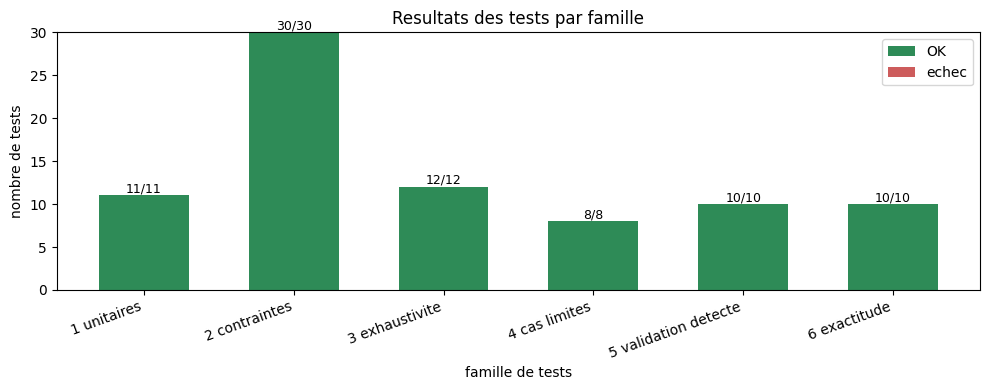

In [17]:
# Nombre d'OK et d'echecs par famille.
par_famille = (recap_tests.assign(ok=recap_tests["resultat"].eq("OK"))
               .groupby("famille").agg(tests=("resultat", "size"),
                                       OK=("ok", "sum")).reset_index())
par_famille["ECHEC"] = par_famille["tests"] - par_famille["OK"]
display(par_famille)

nb_ok = int((recap_tests["resultat"] == "OK").sum())
nb_echec = int((recap_tests["resultat"] == "ECHEC").sum())
print(f"Total : {nb_ok} tests OK, {nb_echec} echec(s) sur {len(recap_tests)} tests.")
if nb_echec:
    print("\nTests en echec :")
    for _, r in recap_tests[recap_tests["resultat"] == "ECHEC"].iterrows():
        print("Test en echec :", r["test"], ":", r["detail"])

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(par_famille))
ax.bar(x, par_famille["OK"], width=0.6, color="seagreen", label="OK")
ax.bar(x, par_famille["ECHEC"], width=0.6, bottom=par_famille["OK"], color="indianred", label="echec")
ax.set_title("Resultats des tests par famille")
ax.set_xlabel("famille de tests"); ax.set_ylabel("nombre de tests")
ax.set_xticks(x); ax.set_xticklabels(par_famille["famille"], rotation=20, ha="right")
ax.legend()
for i, (o, t) in enumerate(zip(par_famille["OK"], par_famille["tests"])):
    ax.text(i, t, f"{o}/{t}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

**Notre constat :** les 81 tests passent, 0 échec. Chaque famille est au complet : 11 tests
unitaires, 30 contrôles de contraintes sur les trois versions, 12 contrôles d'exhaustivité,
8 cas limites, 10 erreurs injectées toutes refusées, et 10 tests d'exactitude, de
reproductibilité, de performance et de non-régression. La solution est fiable sur les trois
versions. Nous reprenons ces chiffres dans le point final.

# Partie 2 : analyse des gains

Nous mesurons maintenant ce que le client gagne. Toutes nos économies se comptent sur le
**périmètre optimisé**, par rapport à la **situation actuelle à règles égales** (baseline
avec H20 : la ligne trop lourde compte pour un seul camion exceptionnel avant comme après,
voir le point sur l'écart de total plus bas). Les 138 lignes non optimisables sont
chiffrées à part, au pire cas, et n'entrent jamais dans nos économies sauf dans la vision
globale prudente (section finale).

## Section 1 : avant / après, pour les trois versions

Pour chaque version, nous comparons à la situation actuelle : coût, nombre de camions,
nombre de livraisons, et remplissage des camions (médian et moyen, en poids et en volume).

In [18]:
import numpy as np, matplotlib.pyplot as plt

def remplissages(contenu):
    nn = contenu[~contenu["envoi_exceptionnel"]].groupby("camion_id").agg(p=("poids", "sum"), v=("volume", "sum"))
    return nn["p"] / CAP_POIDS * 100, nn["v"] / CAP_VOLUME * 100

# Remplissage de la situation actuelle (baseline H20, hors camion exceptionnel).
remp_avant_poids = []
for (s, pl, dt), gg in opt.groupby(["supplier_id", "plant", "date"]):
    exc = (gg["weight"].values > CAP_POIDS) | (gg["volume"].values > CAP_VOLUME)
    nn = gg[~exc]
    if len(nn):
        remp_avant_poids += [w / CAP_POIDS * 100 for w in charger_camions_vieux(nn["weight"].values, nn["volume"].values)]
remp_avant_poids = np.array(remp_avant_poids)

livraisons_avant = opt.groupby(["supplier_id", "plant", "date"]).ngroups
lignes = [{"situation": "actuelle (H20)", "cout": fmt_eur(baseline_H20), "camions": camions_H20,
           "livraisons": livraisons_avant, "remp. poids median": fmt_pct(np.median(remp_avant_poids)),
           "remp. poids moyen": fmt_pct(np.mean(remp_avant_poids)),
           "remp. volume median": "", "remp. volume moyen": ""}]
for mode in VERSIONS_AFFICHAGE:
    ch = SOLUTIONS[mode]["choix"]; cont = SOLUTIONS[mode]["contenu"]
    cam = sum(b["camions"] for b in ch.values()); liv = sum(b["livraisons"] for b in ch.values())
    rp, rv = remplissages(cont)
    lignes.append({"situation": mode, "cout": fmt_eur(SOLUTIONS[mode]["cout"]), "camions": cam,
                   "livraisons": liv, "remp. poids median": fmt_pct(rp.median()),
                   "remp. poids moyen": fmt_pct(rp.mean()), "remp. volume median": fmt_pct(rv.median()),
                   "remp. volume moyen": fmt_pct(rv.mean())})
avant_apres = pd.DataFrame(lignes)
display(avant_apres)

,situation,cout,camions,livraisons,remp. poids median,remp. poids moyen,remp. volume median,remp. volume moyen
0,actuelle (H20),"143 320,74 €",1604,1599,"1,3 %","4,0 %",,
1,strict,"82 110,82 €",652,651,"2,9 %","10,0 %","1,9 %","3,9 %"
2,intermediaire,"79 095,62 €",618,617,"3,0 %","10,5 %","2,0 %","4,1 %"
3,libre,"74 908,40 €",567,566,"3,5 %","11,5 %","2,2 %","4,5 %"


**Notre constat :** les trois versions réduisent fortement le coût et le nombre de
camions. En version stricte (recommandée), nous passons de 143 320,74 € à 82 110,82 €
(652 camions au lieu de 1 604) ; la version intermédiaire descend à 79 095,62 €, la
version libre à 74 908,40 €. Le remplissage médian d'un camion monte de 1,3 % à 2,9 %
en poids (version stricte) : il reste bas parce qu'un camion ne porte qu'un seul
fournisseur, beaucoup de petits fournisseurs restent dans de petits camions. Le vrai
gain vient du nombre de camions en moins, pas de camions pleins partout. Le remplissage
moyen, lui, passe de 4,0 % à 10,0 % en poids.

## Section 2 : les nouvelles distributions, avant contre après

Nous regardons comment la flotte change. Nous prenons la version stricte pour
l'illustration, puisque c'est notre version recommandée (les autres versions figurent dans
le tableau ci-dessus). Nous comparons : le remplissage des camions (poids puis volume), le
coût par camion, les camions par jour de la semaine, la charge par usine et par jour, et la
part du lundi.

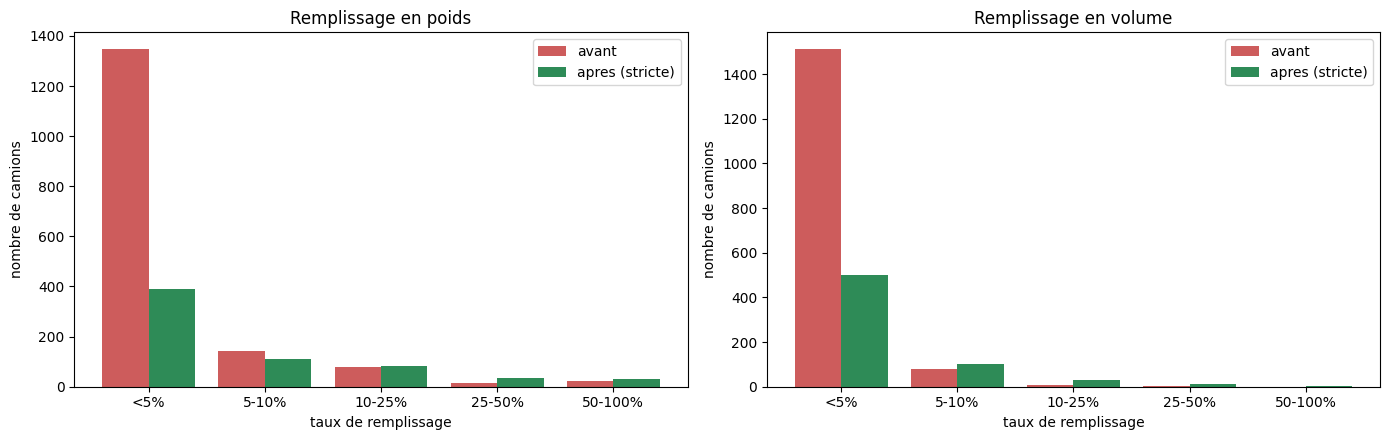

Camions sous 5 % (poids) : avant 1347 ; apres (stricte) 391


In [19]:
cont_strict = SOLUTIONS["strict"]["contenu"]
rp_ap, rv_ap = remplissages(cont_strict)
# remplissage volume avant
remp_avant_vol = []
for (s, pl, dt), gg in opt.groupby(["supplier_id", "plant", "date"]):
    exc = (gg["weight"].values > CAP_POIDS) | (gg["volume"].values > CAP_VOLUME)
    nn = gg[~exc]
    if len(nn):
        # un camion de la baseline : volume reparti proportionnellement au poids des camions decoupes
        tot_w = nn["weight"].sum(); tot_v = nn["volume"].sum()
        for w in charger_camions_vieux(nn["weight"].values, nn["volume"].values):
            remp_avant_vol.append((tot_v * (w / tot_w) if tot_w > 0 else 0) / CAP_VOLUME * 100)
remp_avant_vol = np.array(remp_avant_vol)

bornes = [0, 5, 10, 25, 50, 100.0001]; libelles = ["<5%", "5-10%", "10-25%", "25-50%", "50-100%"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, av, ap, titre in [(a1, remp_avant_poids, rp_ap.values, "Remplissage en poids"),
                          (a2, remp_avant_vol, rv_ap.values, "Remplissage en volume")]:
    ca = pd.cut(av, bins=bornes, labels=libelles, include_lowest=True).value_counts().reindex(libelles)
    cb = pd.cut(ap, bins=bornes, labels=libelles, include_lowest=True).value_counts().reindex(libelles)
    x = np.arange(len(libelles))
    ax.bar(x - 0.2, ca.values, width=0.4, label="avant", color="indianred")
    ax.bar(x + 0.2, cb.values, width=0.4, label="apres (stricte)", color="seagreen")
    ax.set_title(titre); ax.set_xlabel("taux de remplissage"); ax.set_ylabel("nombre de camions")
    ax.set_xticks(x); ax.set_xticklabels(libelles); ax.legend()
plt.tight_layout(); plt.show()
print("Camions sous 5 % (poids) : avant", int((remp_avant_poids < 5).sum()), "; apres (stricte)", int((rp_ap < 5).sum()))

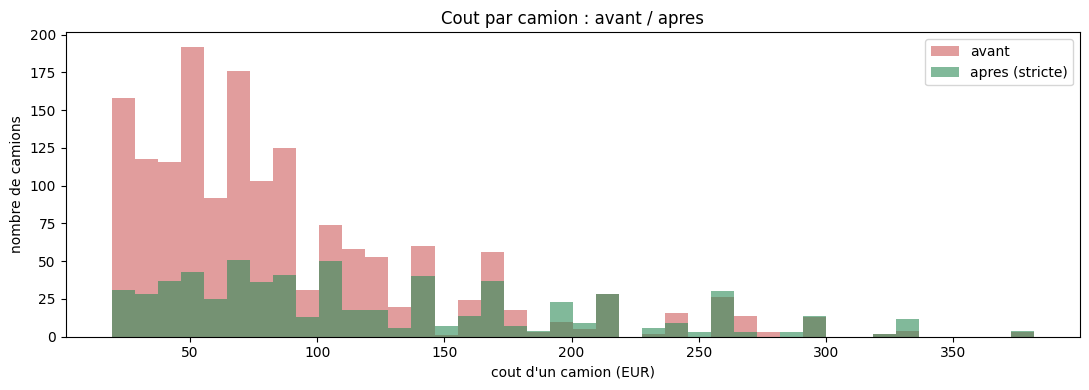

Cout moyen par camion : avant 89,35 € ; apres (stricte) 125,94 €
Cout median par camion : avant 71,35 € ; apres (stricte) 101,12 €


In [20]:
# Cout par camion : avant / apres (version stricte).
cout_avant_camion = []
for (s, pl, dt), gg in opt.groupby(["supplier_id", "plant", "date"]):
    lg = gg["ligne_grille"].iloc[0]
    exc = (gg["weight"].values > CAP_POIDS) | (gg["volume"].values > CAP_VOLUME)
    nn = gg[~exc]
    if len(nn):
        cout_avant_camion += [prix_camion(lg, w) for w in charger_camions_vieux(nn["weight"].values, nn["volume"].values)]
    cout_avant_camion += [prix_exceptionnel(lg)] * int(exc.sum())
cout_apres_camion = []
for cid, gg in cont_strict.groupby("camion_id"):
    lg = COUPLES[(gg["supplier_id"].iloc[0], gg["plant"].iloc[0])]["ligne"]
    cout_apres_camion.append(prix_exceptionnel(lg) if gg["envoi_exceptionnel"].iloc[0] else prix_camion(lg, gg["poids"].sum()))

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(cout_avant_camion, bins=40, color="indianred", alpha=0.6, label="avant")
ax.hist(cout_apres_camion, bins=40, color="seagreen", alpha=0.6, label="apres (stricte)")
ax.set_title("Cout par camion : avant / apres"); ax.set_xlabel("cout d'un camion (EUR)")
ax.set_ylabel("nombre de camions"); ax.legend()
plt.tight_layout(); plt.show()
print("Cout moyen par camion : avant", fmt_eur(np.mean(cout_avant_camion)), "; apres (stricte)", fmt_eur(np.mean(cout_apres_camion)))
print("Cout median par camion : avant", fmt_eur(np.median(cout_avant_camion)), "; apres (stricte)", fmt_eur(np.median(cout_apres_camion)))

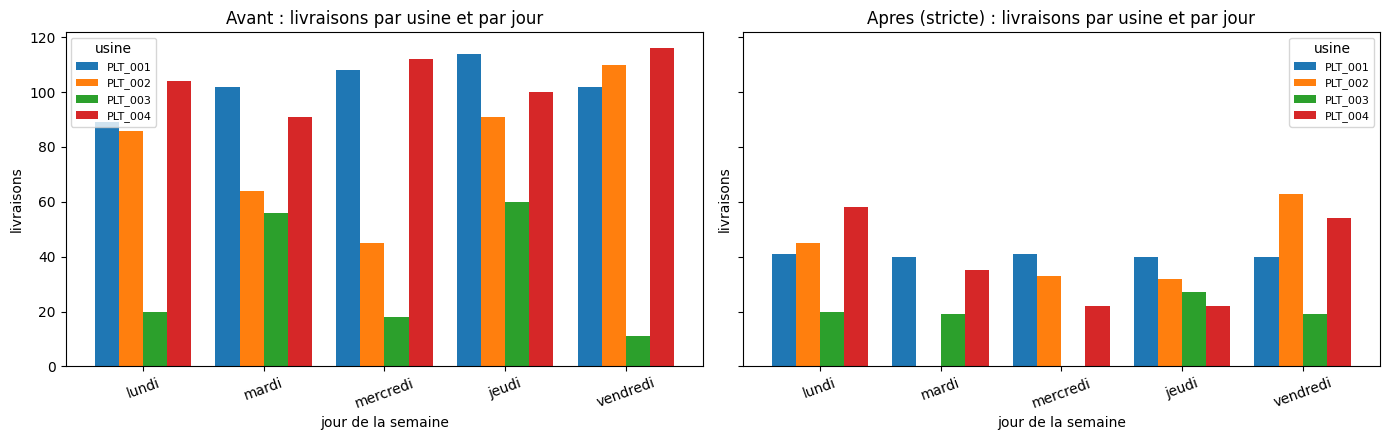

,version,part du lundi
0,strict,"25,2 %"
1,intermediaire,"23,2 %"
2,libre,"20,1 %"
3,situation actuelle,"18,7 %"


In [21]:
# Camions par jour de la semaine : avant / apres (version stricte). On reutilise les outils du moteur.
def charge_avant_jour():
    from collections import defaultdict
    t = defaultdict(lambda: defaultdict(int))
    for (s, pl, dt), gg in opt.groupby(["supplier_id", "plant", "date"]):
        t[pl][pd.Timestamp(dt).weekday()] += 1
    return t

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
tracer_charge(charge_avant_jour(), "Avant : livraisons par usine et par jour", a1)
tracer_charge(charge_par_jour_semaine(SOLUTIONS["strict"]["choix"]), "Apres (stricte) : livraisons par usine et par jour", a2)
plt.tight_layout(); plt.show()

# Part du lundi par version.
lundi = pd.DataFrame([{"version": m, "part du lundi": fmt_pct(part_lundi(SOLUTIONS[m]["choix"])[2])} for m in VERSIONS_AFFICHAGE])
lundi.loc[len(lundi)] = {"version": "situation actuelle",
                         "part du lundi": fmt_pct(sum(1 for (s, pl, dt) in opt.groupby(["supplier_id", "plant", "date"]).groups
                                                       if pd.Timestamp(dt).weekday() == 0) / livraisons_avant * 100)}
display(lundi)

**Notre constat :** après consolidation, les camions presque vides (moins de 5 % remplis
en poids) fondent : de 1 347 à 391 en version stricte. Le coût par camion monte, puisque
nous mettons plus de choses dans chaque camion (de 89,35 € à 125,94 € en moyenne), mais le
nombre de camions chute fortement, donc le coût total baisse. La charge reste répartie sur
les cinq jours : la part du lundi est de 25,2 % en version stricte, contre 18,7 % pour les
besoins actuels (déjà étalés, le jeudi étant le jour le plus chargé aujourd'hui). Plus la
version est régulière, plus le lundi se charge (20,1 % en libre, 23,2 % en intermédiaire,
25,2 % en stricte), car le lissage dispose de moins de profils proches en coût pour répartir
les jours ; aucun jour ne domine pour autant.

## Section 2 bis : l'apport de la semaine du 02/11

Les livraisons peuvent maintenant partir dès le lundi 02/11, soit 7 jours avant le premier
besoin du 09/11 ; le calendrier compte 35 jours ouvrés sur 7 semaines au lieu de 30 sur 6.
Les besoins, eux, ne changent pas (du 09/11 au 18/12). Nous mesurons ce que cette semaine
supplémentaire apporte : combien de lignes partent cette semaine-là et pour combien de
couples, combien de profils redeviennent possibles, et ce que cela fait gagner à chaque
version par rapport à l'ancien calendrier qui commençait le 09/11. Pour comparer, nous
relançons tout le moteur sur l'ancien calendrier.

In [22]:
# Nous comparons le calendrier actuel (livraisons des le 02/11) a l'ancien (debut 09/11),
# en recalculant les profils et le cout de chaque version. Nous remplacons temporairement le
# calendrier dans l'espace de noms du moteur (_ns), puis nous le restaurons.
def couts_pour_calendrier(premier_jour):
    """Recalcule, pour un premier jour de livraison donne, le cout de chaque version
    (etape 1 avant lissage et cout final apres lissage) et les profils possibles."""
    d0b = pd.Timestamp(premier_jour); d1b = opt["date"].max()
    lundi0b = d0b - pd.Timedelta(int(d0b.weekday()), unit="D")
    jo = pd.DatetimeIndex([d for d in pd.date_range(d0b, d1b, freq="D")
                           if d.weekday() < 5 and not semaine_fermee(d)])
    cles = ["jours_ouvres", "lundi0", "d0", "d1", "DATES_PROFIL", "SEM_PROFIL"]
    sauve = {k: _ns[k] for k in cles}
    try:
        _ns["jours_ouvres"] = jo; _ns["lundi0"] = lundi0b; _ns["d0"] = d0b; _ns["d1"] = d1b
        _ns["DATES_PROFIL"] = [dates_profil(p) for p in PROFILS]
        _ns["SEM_PROFIL"] = [semaines_du_profil(d) for d in _ns["DATES_PROFIL"]]
        res = {"jours_ouvres": len(jo)}
        for mode in MODES:
            cand = evaluer_tous(idx_tous, mode=mode)
            best = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand.items() if v}
            ch, co = lissage(cand, best, TOLERANCE_LISSAGE)
            res[mode] = {"etape1": sum(b["cout"] for b in best.values()), "cout": co,
                         "paires_possibles": sum(len(v) for v in cand.values()),
                         "possibles_par_couple": {cle: len(v) for cle, v in cand.items()}}
    finally:
        for k in cles:
            _ns[k] = sauve[k]
    return res

ancien = couts_pour_calendrier("2026-11-09")   # ancien calendrier, sans la semaine du 02/11
actuel = couts_pour_calendrier("2026-11-02")   # calendrier actuel, livraisons des le 02/11
print("Jours ouvres :", ancien["jours_ouvres"], "(ancien, debut 09/11) contre",
      actuel["jours_ouvres"], "(actuel, debut 02/11).")

rows = []
for mode in VERSIONS_AFFICHAGE:
    cont = SOLUTIONS[mode]["contenu"]; dl = pd.to_datetime(cont["date_livraison"])
    sem1 = cont[(dl >= pd.Timestamp("2026-11-02")) & (dl <= pd.Timestamp("2026-11-06")) & (~cont["envoi_exceptionnel"])]
    gagnes = sum(1 for cle in actuel[mode]["possibles_par_couple"]
                 if actuel[mode]["possibles_par_couple"][cle] > ancien[mode]["possibles_par_couple"].get(cle, 0))
    rows.append({"version": mode,
                 "lignes la semaine du 02/11": len(sem1),
                 "couples servis cette semaine": sem1.groupby(["supplier_id", "plant"]).ngroups,
                 "camions cette semaine": sem1["camion_id"].nunique(),
                 "paires couple x profil en plus": actuel[mode]["paires_possibles"] - ancien[mode]["paires_possibles"],
                 "couples qui gagnent un profil": gagnes,
                 "cout ancien calendrier": fmt_eur(ancien[mode]["cout"]),
                 "cout actuel": fmt_eur(actuel[mode]["cout"]),
                 "gain du 02/11": fmt_eur(ancien[mode]["cout"] - actuel[mode]["cout"])})
apport = pd.DataFrame(rows)
display(apport)

cont = SOLUTIONS["strict"]["contenu"]; dl = pd.to_datetime(cont["date_livraison"])
sem1 = cont[(dl >= pd.Timestamp("2026-11-02")) & (dl <= pd.Timestamp("2026-11-06")) & (~cont["envoi_exceptionnel"])]
print("Version stricte : la semaine du 02/11 sert", sem1.groupby(["supplier_id", "plant"]).ngroups,
      "couples en", sem1["camion_id"].nunique(), "camions, soit", len(sem1), "lignes avancees.")

Jours ouvres : 30 (ancien, debut 09/11) contre 35 (actuel, debut 02/11).


,version,lignes la semaine du 02/11,couples servis cette semaine,camions cette semaine,paires couple x profil en plus,couples qui gagnent un profil,cout ancien calendrier,cout actuel,gain du 02/11
0,strict,242,56,56,1674,129,"83 394,55 €","82 110,82 €","1 283,73 €"
1,intermediaire,188,49,49,1674,129,"80 754,80 €","79 095,62 €","1 659,18 €"
2,libre,164,62,62,1674,129,"74 908,28 €","74 908,40 €","-0,12 €"


Version stricte : la semaine du 02/11 sert 56 couples en 56 camions, soit 242 lignes avancees.


**Notre constat :** la semaine du 02/11 ajoute 5 jours ouvrés (35 au lieu de 30) et rend
possibles 1 674 paires couple x profil de plus ; 129 couples sur 171 gagnent au moins un profil
possible. En version stricte (recommandée), 56 couples sont servis dès cette semaine (242 lignes
avancées en 56 camions), ce qui fait gagner 1 283,73 € par rapport à l'ancien calendrier
(82 110,82 € au lieu de 83 394,55 €). La version intermédiaire gagne davantage, 1 659,18 €
(79 095,62 € au lieu de 80 754,80 €). La version libre, elle, ne gagne presque rien : son coût
d'étape 1 est inchangé, car elle pouvait déjà avancer ses besoins dans les jours existants, et
après lissage elle coûte même 0,12 € de plus (74 908,40 € au lieu de 74 908,28 €), un écart que
nous expliquons juste après. Autrement dit, la semaine du 02/11 profite surtout aux versions
régulières, qui doivent tenir le rythme chaque semaine.

### Pourquoi la version libre coûte 0,12 € de plus qu'avant

La version libre coûtait 74 908,28 € avec l'ancien calendrier et coûte 74 908,40 € avec le
calendrier actuel, alors que nous avons seulement ajouté des possibilités de livraison. Nous
vérifions l'origine de cet écart de 0,12 €, en séparant l'étape 1 (le meilleur profil de chaque
couple, avant lissage) du lissage.

In [23]:
# L'ecart de 0,12 EUR de la version libre : etape 1 (avant lissage) puis lissage.
print("Version libre, etape 1 (avant lissage) :")
print("  ancien calendrier :", fmt_eur(ancien["libre"]["etape1"]))
print("  calendrier actuel :", fmt_eur(actuel["libre"]["etape1"]))
print("  difference        :", fmt_eur(actuel["libre"]["etape1"] - ancien["libre"]["etape1"]))
print("Version libre, apres lissage :")
print("  ancien calendrier :", fmt_eur(ancien["libre"]["cout"]))
print("  calendrier actuel :", fmt_eur(actuel["libre"]["cout"]))
print("  difference        :", fmt_eur(actuel["libre"]["cout"] - ancien["libre"]["cout"]))

Version libre, etape 1 (avant lissage) :
  ancien calendrier : 74 843,82 €
  calendrier actuel : 74 843,82 €
  difference        : 0,00 €
Version libre, apres lissage :
  ancien calendrier : 74 908,28 €
  calendrier actuel : 74 908,40 €
  difference        : 0,12 €


**Notre constat :** à l'étape 1, avant lissage, la version libre coûte exactement le même
montant qu'avant (74 843,82 € dans les deux cas) : ajouter la semaine du 02/11 ne lui ouvre
aucun profil moins cher, car elle pouvait déjà avancer ses besoins dans les jours déjà
disponibles. L'écart de 0,12 € naît entièrement au lissage. Le lissage ne cherche pas le coût
minimal : parmi les profils dont le coût dépasse le meilleur de 2 % au plus, il retient celui
qui équilibre le mieux la charge de la semaine. Avec la semaine du 02/11 en plus, la charge par
jour se présente autrement, et pour un couple le lissage préfère désormais un profil légèrement
plus cher (dans la tolérance) qui équilibre mieux. Le coût optimal, lui, n'a pas augmenté :
l'écart de 0,12 € est le prix d'un meilleur équilibre dans la semaine, pas une régression.

## Section 3 : où se concentre l'économie

Nous regardons quelle part de l'économie totale vient de chaque usine, de chaque
fournisseur et de chaque couple. Nous mesurons aussi la concentration (part des 20 premiers
couples) et nous signalons les couples qui ne gagnent rien, en expliquant pourquoi.

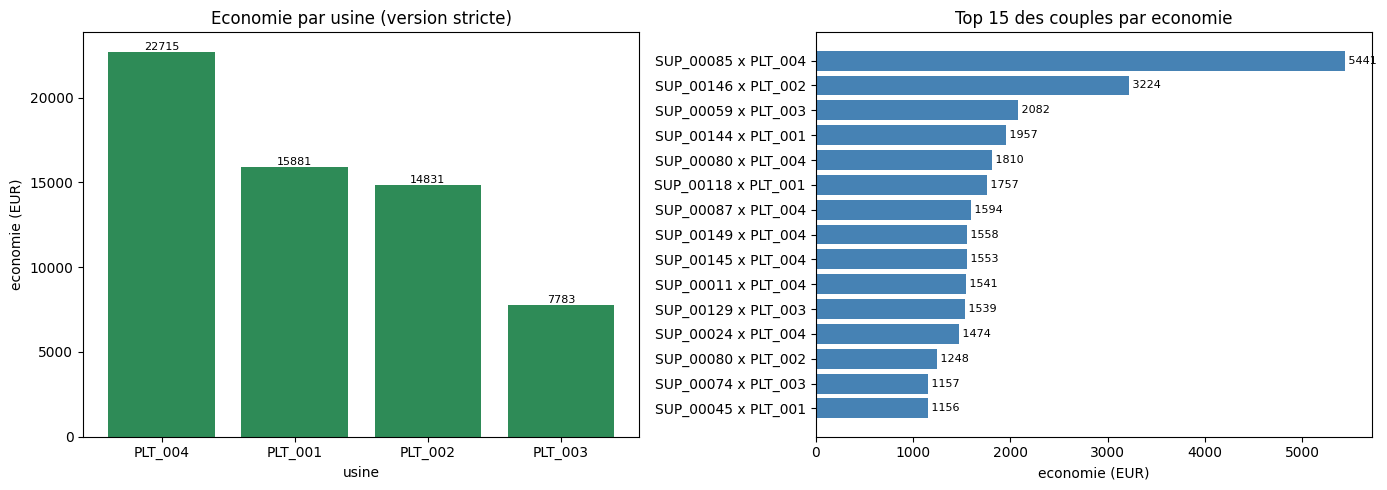

Economie par usine :


,economie,part %
plant,,
PLT_004,"22 714,79 €","37,1 %"
PLT_001,"15 880,85 €","25,9 %"
PLT_002,"14 830,89 €","24,2 %"
PLT_003,"7 783,39 €","12,7 %"


Economie totale (version libre) : 61 209,92 €
Fournisseur le plus rentable : SUP_00085 : 5 586,75 €
Couple le plus rentable : SUP_00085 x PLT_004 : 5 440,74 €


In [24]:
# Economie par couple (version stricte, sur le perimetre).
eco = pd.DataFrame([{"supplier_id": s, "plant": pl,
                     "eco": cout_actuel_couple((s, pl)) - SOLUTIONS["strict"]["choix"][(s, pl)]["cout"]}
                    for (s, pl) in COUPLES])
eco_total = eco["eco"].sum()
eco_usine = eco.groupby("plant")["eco"].sum().sort_values(ascending=False)
eco_fourn = eco.groupby("supplier_id")["eco"].sum().sort_values(ascending=False)
eco_tri = eco.sort_values("eco", ascending=False).reset_index(drop=True)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
b = a1.bar(eco_usine.index, eco_usine.values, color="seagreen")
a1.set_title("Economie par usine (version stricte)"); a1.set_xlabel("usine"); a1.set_ylabel("economie (EUR)")
for bb, v in zip(b, eco_usine.values):
    a1.text(bb.get_x() + bb.get_width() / 2, v, str(round(v)), ha="center", va="bottom", fontsize=8)
top15 = eco_tri.head(15); etiq = top15["supplier_id"] + " x " + top15["plant"]
a2.barh(etiq, top15["eco"], color="steelblue"); a2.invert_yaxis()
a2.set_title("Top 15 des couples par economie"); a2.set_xlabel("economie (EUR)")
for i, v in enumerate(top15["eco"]):
    a2.text(v, i, " " + str(round(v)), va="center", fontsize=8)
plt.tight_layout(); plt.show()

# Part en euros et en %.
tab_usine = pd.DataFrame({"economie": [fmt_eur(v) for v in eco_usine.values],
                          "part %": [fmt_pct(v / eco_total * 100) for v in eco_usine.values]},
                         index=eco_usine.index)
print("Economie par usine :"); display(tab_usine)
print("Economie totale (version libre) :", fmt_eur(eco_total))
print("Fournisseur le plus rentable :", eco_fourn.index[0], ":", fmt_eur(eco_fourn.iloc[0]))
print("Couple le plus rentable :", eco_tri.iloc[0]["supplier_id"], "x", eco_tri.iloc[0]["plant"],
      ":", fmt_eur(eco_tri.iloc[0]["eco"]))

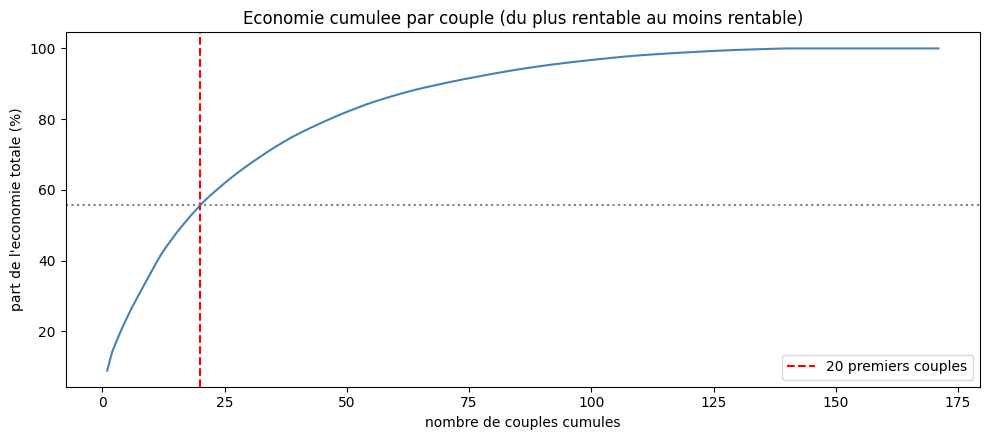

Part de l'economie portee par les 10 premiers couples : 36,8 %
Part de l'economie portee par les 20 premiers couples : 55,6 %
Couples a gain nul ou negligeable (version stricte) : 31 sur 171
  dont livrant deja en un seul envoi : 17
  dont autant de livraisons qu'aujourd'hui (besoins dans des semaines differentes) : 14


,supplier_id,plant,lignes,envois actuels,livraisons (stricte),profil choisi,pourquoi
0,SUP_00015,PLT_004,2,2,2,1 / semaine : jeudi,autant de livraisons qu'aujourd'hui (besoins dans des semaines dif...
1,SUP_00016,PLT_002,1,1,1,1 / semaine : jeudi,livre deja en un seul envoi : rien a regrouper
2,SUP_00016,PLT_003,2,2,2,1 / semaine : lundi,autant de livraisons qu'aujourd'hui (besoins dans des semaines dif...
3,SUP_00005,PLT_001,4,3,3,1 / semaine : jeudi,autant de livraisons qu'aujourd'hui (besoins dans des semaines dif...
4,SUP_00001,PLT_004,6,2,2,1 / semaine : jeudi,autant de livraisons qu'aujourd'hui (besoins dans des semaines dif...
5,SUP_00008,PLT_002,4,3,3,1 / semaine : mercredi,autant de livraisons qu'aujourd'hui (besoins dans des semaines dif...
6,SUP_00009,PLT_004,1,1,1,1 / semaine : jeudi,livre deja en un seul envoi : rien a regrouper
7,SUP_00086,PLT_001,4,3,3,1 / semaine : vendredi,autant de livraisons qu'aujourd'hui (besoins dans des semaines dif...
8,SUP_00060,PLT_004,4,4,4,1 / semaine : jeudi,autant de livraisons qu'aujourd'hui (besoins dans des semaines dif...
9,SUP_00055,PLT_003,6,3,3,1 / semaine : mardi,autant de livraisons qu'aujourd'hui (besoins dans des semaines dif...


In [25]:
# Concentration : courbe de l'economie cumulee, part des 20 premiers couples.
cum = eco_tri["eco"].cumsum() / eco_total * 100
part_top10 = eco_tri.head(10)["eco"].sum() / eco_total * 100
part_top20 = eco_tri.head(20)["eco"].sum() / eco_total * 100
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(range(1, len(cum) + 1), cum.values, color="steelblue")
ax.axvline(20, color="red", linestyle="--", label="20 premiers couples")
ax.axhline(part_top20, color="grey", linestyle=":")
ax.set_title("Economie cumulee par couple (du plus rentable au moins rentable)")
ax.set_xlabel("nombre de couples cumules"); ax.set_ylabel("part de l'economie totale (%)")
ax.legend(); plt.tight_layout(); plt.show()
print("Part de l'economie portee par les 10 premiers couples :", fmt_pct(part_top10))
print("Part de l'economie portee par les 20 premiers couples :", fmt_pct(part_top20))

# Couples qui ne gagnent rien, raison VERIFIEE sur les donnees (nombre de lignes, envois actuels,
# livraisons de la version stricte, profil choisi). Nous n'ecrivons que ce que les donnees montrent.
faibles = eco_tri[eco_tri["eco"] <= 1.0].copy()
lignes_f = []
for _, r in faibles.iterrows():
    cle = (r["supplier_id"], r["plant"]); c = COUPLES[cle]
    nb_envois_actuels = c["df"].groupby("date").ngroups
    nb_lignes = len(c["besoins"]) + len(c["exc_dates"])
    liv = SOLUTIONS["strict"]["choix"][cle]["livraisons"]
    profil = PROFILS[SOLUTIONS["strict"]["choix"][cle]["idx"]]["libelle"]
    if nb_envois_actuels <= 1:
        raison = "livre deja en un seul envoi : rien a regrouper"
    elif liv == nb_envois_actuels:
        raison = "autant de livraisons qu'aujourd'hui (besoins dans des semaines differentes) : rien a regrouper"
    else:
        raison = "regroupement sans effet sur le prix de la grille"
    lignes_f.append({"supplier_id": cle[0], "plant": cle[1], "lignes": nb_lignes,
                     "envois actuels": nb_envois_actuels, "livraisons (stricte)": liv,
                     "profil choisi": profil, "pourquoi": raison})
faibles_tab = pd.DataFrame(lignes_f)
n_un_envoi = int((faibles_tab["envois actuels"] <= 1).sum())
n_meme_nb = int(((faibles_tab["envois actuels"] > 1) & (faibles_tab["livraisons (stricte)"] == faibles_tab["envois actuels"])).sum())
print("Couples a gain nul ou negligeable (version stricte) :", len(faibles_tab), "sur", len(eco))
print("  dont livrant deja en un seul envoi :", n_un_envoi)
print("  dont autant de livraisons qu'aujourd'hui (besoins dans des semaines differentes) :", n_meme_nb)
display(faibles_tab.head(12))


**Notre constat :** l'économie est concentrée. Les 20 premiers couples portent 55,6 % de
l'économie totale (36,8 % pour les 10 premiers). L'usine PLT_004 apporte la plus grosse part
(22 714,79 €, 37,1 %), devant PLT_001 (15 880,85 €, 25,9 %) et PLT_002 (14 830,89 €, 24,2 %) ;
PLT_003, la plus petite, apporte 7 783,39 €. Le couple le plus rentable, SUP_00085 x PLT_004,
économise à lui seul 5 440,74 €. À l'opposé, 31 couples ne gagnent rien, et nous l'avons
vérifié couple par couple : 17 d'entre eux livrent déjà en un seul envoi, et les 14 autres
font déjà autant de livraisons qu'aujourd'hui parce que leurs besoins tombent dans des
semaines différentes (une livraison par semaine), si bien qu'il n'y a rien à regrouper dans
la fenêtre des 7 jours. Pour aucun d'eux le nombre de trajets ne baisse.

## Section 4 : réalisé contre potentiel, et l'objectif de 35 %

Au milestone 2, nous avions estimé un potentiel d'économie par un regroupement
hebdomadaire simple (un envoi par semaine le lundi), enregistré dans
`potentiel_couples.csv`. Nous comparons ce potentiel à ce que notre moteur réalise
vraiment, au global et par couple, puis à notre objectif d'au moins 35 %.

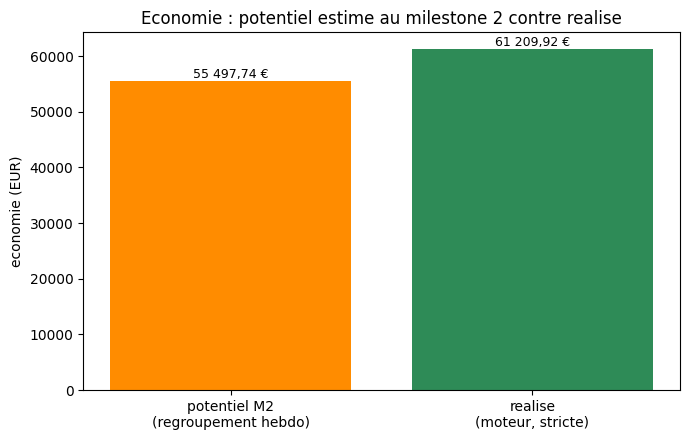

Potentiel estime au milestone 2 : 55 497,74 €
Realise par le moteur (version stricte) : 61 209,92 € soit 10,3 % de plus que le potentiel
Couples ou le realise depasse le potentiel : 99
Couples ou le realise est en dessous : 8

Objectif : au moins 35 % du perimetre, soit 50 162,26 €


,version,economie,economie %,objectif 35 % atteint
0,strict,"61 209,92 €","42,7 %",oui
1,intermediaire,"64 225,12 €","44,8 %",oui
2,libre,"68 412,34 €","47,7 %",oui


In [26]:
potentiel = pd.read_csv("../data/processed/potentiel_couples.csv")
comp = eco.merge(potentiel[["supplier_id", "plant", "gain_eur"]], on=["supplier_id", "plant"], how="left")
comp = comp.rename(columns={"eco": "realise", "gain_eur": "potentiel_M2"}).fillna({"potentiel_M2": 0.0})
realise_total = comp["realise"].sum(); potentiel_total = comp["potentiel_M2"].sum()

fig, ax = plt.subplots(figsize=(7, 4.5))
b = ax.bar(["potentiel M2\n(regroupement hebdo)", "realise\n(moteur, stricte)"],
           [potentiel_total, realise_total], color=["darkorange", "seagreen"])
ax.set_title("Economie : potentiel estime au milestone 2 contre realise"); ax.set_ylabel("economie (EUR)")
for bb, v in zip(b, [potentiel_total, realise_total]):
    ax.text(bb.get_x() + bb.get_width() / 2, v, fmt_eur(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()
print("Potentiel estime au milestone 2 :", fmt_eur(potentiel_total))
print("Realise par le moteur (version stricte) :", fmt_eur(realise_total),
      "soit", fmt_pct(realise_total / potentiel_total * 100 - 100), "de plus que le potentiel")
print("Couples ou le realise depasse le potentiel :", int((comp["realise"] > comp["potentiel_M2"] + 1).sum()))
print("Couples ou le realise est en dessous :", int((comp["realise"] < comp["potentiel_M2"] - 1).sum()))

# Objectif 35 % sur le perimetre, pour les trois versions.
print("\nObjectif : au moins 35 % du perimetre, soit", fmt_eur(0.35 * baseline_H20))
obj = []
for mode in VERSIONS_AFFICHAGE:
    e = baseline_H20 - SOLUTIONS[mode]["cout"]
    obj.append({"version": mode, "economie": fmt_eur(e), "economie %": fmt_pct(e / baseline_H20 * 100),
                "objectif 35 % atteint": "oui" if e / baseline_H20 * 100 >= 35 else "non"})
display(pd.DataFrame(obj))

**Notre constat :** le moteur fait mieux que le potentiel estimé au milestone 2. En version
stricte, il réalise 61 209,92 € d'économie contre 55 497,74 € estimés, soit environ 10,3 % de
plus, et le réalisé dépasse le potentiel pour 99 couples sur 171 (il reste en dessous pour 8).
L'écart s'explique : le potentiel du milestone 2 supposait un seul regroupement par semaine le
lundi, alors que notre moteur choisit le meilleur profil de chaque couple et regroupe plus
finement dans la fenêtre des 7 jours ; à l'inverse, pour quelques couples, l'engagement de la
version stricte (tenir le rythme chaque semaine) coûte un peu plus que le regroupement
hebdomadaire simple. Les trois versions dépassent largement l'objectif de 35 % sur le périmètre
(42,7 % en stricte, 44,8 % en intermédiaire, 47,7 % en libre).

## Section 5 : la vision globale, avec les 138 lignes non optimisables

Pour être honnêtes avec le client, nous ajoutons les 138 lignes non optimisables, chiffrées
au pire cas (un camion plein chacune, 35 032,42 €). Elles sont identiques avant et après :
elles ne changent pas l'économie en euros, mais elles abaissent l'économie en pourcentage,
parce qu'elles pèsent dans le total sans que nous puissions agir dessus. C'est volontaire :
nous préférons annoncer un gain prudent, jamais exagéré.

,version,cout total avant,cout total apres,economie EUR,economie % perimetre,economie % global prudent
0,strict,"178 353,16 €","117 143,24 €","61 209,92 €","42,7 %","34,3 %"
1,intermediaire,"178 353,16 €","114 128,04 €","64 225,12 €","44,8 %","36,0 %"
2,libre,"178 353,16 €","109 940,82 €","68 412,34 €","47,7 %","38,4 %"


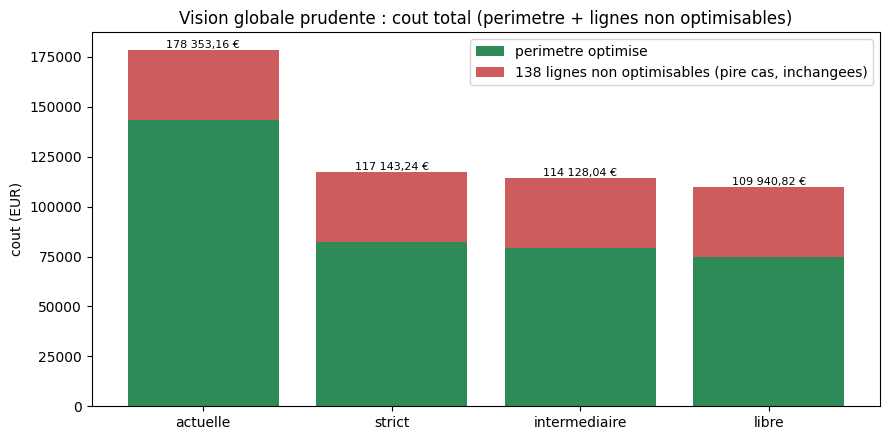

In [27]:
COUT_INCONNUES_PIRE = COUT_INCONNUES
rows = []
for mode in VERSIONS_AFFICHAGE:
    cout = SOLUTIONS[mode]["cout"]
    avant_total = baseline_H20 + COUT_INCONNUES_PIRE
    apres_total = cout + COUT_INCONNUES_PIRE
    eco_eur = baseline_H20 - cout
    rows.append({"version": mode,
                 "cout total avant": fmt_eur(avant_total), "cout total apres": fmt_eur(apres_total),
                 "economie EUR": fmt_eur(eco_eur),
                 "economie % perimetre": fmt_pct(eco_eur / baseline_H20 * 100),
                 "economie % global prudent": fmt_pct(eco_eur / avant_total * 100)})
vision = pd.DataFrame(rows)
display(vision)

fig, ax = plt.subplots(figsize=(9, 4.5))
noms = ["actuelle"] + list(VERSIONS_AFFICHAGE)
perim = [baseline_H20] + [SOLUTIONS[m]["cout"] for m in VERSIONS_AFFICHAGE]
ax.bar(noms, perim, color="seagreen", label="perimetre optimise")
ax.bar(noms, [COUT_INCONNUES_PIRE] * len(noms), bottom=perim, color="indianred",
       label="138 lignes non optimisables (pire cas, inchangees)")
ax.set_title("Vision globale prudente : cout total (perimetre + lignes non optimisables)")
ax.set_ylabel("cout (EUR)")
for i, tot in enumerate([p + COUT_INCONNUES_PIRE for p in perim]):
    ax.text(i, tot, fmt_eur(tot), ha="center", va="bottom", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

**Notre constat :** en vision globale prudente, la version stricte fait passer le coût total
de 178 353,16 € à 117 143,24 €. L'économie en euros est la même que sur le périmètre
(61 209,92 €), mais en pourcentage du total elle passe de 42,7 % (sur le périmètre) à 34,3 %
(sur le total), parce que les 138 lignes non optimisables pèsent au pire cas sans bouger. C'est
notre plancher garanti : la réalité de ces lignes ne peut être que meilleure. À titre de
comparaison, la version libre descend à 109 940,82 € (38,4 % du total).

## Point à vérifier : l'écart entre 178 455 € et 178 353,16 €

Le milestone 2 annonce une situation actuelle complète de **178 455 €**. Le milestone 3
utilise **178 353,16 €**. Nous vérifions l'écart et expliquons son origine.

In [28]:
total_M2 = baseline_M2 + COUT_INCONNUES          # situation complete du milestone 2 (ligne lourde coupee)
total_M3 = baseline_H20 + COUT_INCONNUES          # vision du milestone 3 (ligne lourde = 1 camion exceptionnel)
print("Milestone 2 (situation complete)  :", fmt_eur(total_M2))
print("Milestone 3 (vision complete H20) :", fmt_eur(total_M3))
print("Ecart                             :", fmt_eur(total_M2 - total_M3))
print()
print("Origine de l'ecart : la seule ligne de 26,9 t (SUP_00074 x PLT_003).")
print("  Milestone 2 : elle est coupee en deux camions (H13) :", fmt_eur(baseline_M2 - baseline_H20 + prix_exceptionnel("150")),
      "pour 2 camions")
print("  Milestone 3 : elle part en un seul camion exceptionnel '>4000' (H20) :", fmt_eur(prix_exceptionnel("150")))
print("  Les 138 lignes non optimisables coutent 35 032,42 EUR dans les deux cas.")

Milestone 2 (situation complete)  : 178 454,85 €
Milestone 3 (vision complete H20) : 178 353,16 €
Ecart                             : 101,69 €

Origine de l'ecart : la seule ligne de 26,9 t (SUP_00074 x PLT_003).
  Milestone 2 : elle est coupee en deux camions (H13) : 483,42 € pour 2 camions
  Milestone 3 : elle part en un seul camion exceptionnel '>4000' (H20) : 381,73 €
  Les 138 lignes non optimisables coutent 35 032,42 EUR dans les deux cas.


**Notre constat :** l'écart est de 101,69 €, et il vient entièrement de la ligne de 26,9 t.
Au milestone 2, nous la coupions en deux camions (H13). Au milestone 3, nous la traitons
comme un envoi exceptionnel, un seul camion au tarif ">4000" (H20), un peu moins cher. Les
138 lignes non optimisables (35 032,42 €) sont identiques dans les deux cas.

**Ce que nous proposons (à valider par l'équipe) :** utiliser **178 353,16 €** (H20)
partout. Toute notre analyse du milestone 3 et du milestone 4 compare la situation actuelle
et la solution **à règles égales** : la ligne de 26,9 t est traitée en envoi exceptionnel
avant comme après. Mélanger les deux conventions fausserait l'économie. Nous gardons
**178 455 €** comme simple rappel du pire cas du milestone 2 (ligne coupée). Nous ne
tranchons pas seuls : c'est une décision d'équipe, mais notre recommandation est claire.

## Corrections apportées aux milestones précédents

Nous avions le droit de corriger les milestones 1, 2 et 3 si un test révélait une vraie
erreur, sans jamais changer une décision de l'équipe : un camion par couple et par jour ;
au plus 7 jours d'avance, jamais de retard ; des livraisons possibles dès le lundi 02/11 ;
la ligne de 26,9 t en envoi exceptionnel ; les trois versions du profil, la version stricte
recommandée par défaut ; les mêmes règles de lissage ; les lignes du 01/01/2027 retirées ;
les poids manquants non imputés ; les fournisseurs sans distance exclus.

In [29]:
nb_echec = int((pd.DataFrame(RESULTATS)["resultat"] == "ECHEC").sum())
if nb_echec == 0:
    print("Aucune correction necessaire :", len(RESULTATS), "tests passent, 0 echec.")
    print("Le pipeline retire bien les lignes a quantite 0 et du 01/01/2027.")
    print("La situation actuelle du milestone 2 (143 422,43 €) est retrouvee au centime.")
    print("Les trois versions du moteur retrouvent les chiffres de comparaison_versions.csv.")
    print("Toutes les contraintes du client sont respectees sur les trois versions.")
    print("Seul point d'attention : l'ecart 178 455 € / 178 353,16 €, un choix de convention, pas une erreur.")
else:
    print("Tests en echec a examiner :", nb_echec)
    for _, r in pd.DataFrame(RESULTATS).query("resultat == 'ECHEC'").iterrows():
        print("Test en echec :", r["test"], ":", r["detail"])


Aucune correction necessaire : 81 tests passent, 0 echec.
Le pipeline retire bien les lignes a quantite 0 et du 01/01/2027.
La situation actuelle du milestone 2 (143 422,43 €) est retrouvee au centime.
Les trois versions du moteur retrouvent les chiffres de comparaison_versions.csv.
Toutes les contraintes du client sont respectees sur les trois versions.
Seul point d'attention : l'ecart 178 455 € / 178 353,16 €, un choix de convention, pas une erreur.


**Notre constat :** les 81 tests passent, donc aucune correction n'est nécessaire et les
milestones 1, 2 et 3 restent inchangés. Le pipeline retire bien les lignes à quantité 0 et du
01/01/2027, la situation actuelle du milestone 2 (143 422,43 €) est retrouvée au centime, et
les trois versions du moteur retrouvent exactement les chiffres de `comparaison_versions.csv`.
Le seul écart constaté (178 455 € au milestone 2 contre 178 353,16 € au milestone 3) est un
choix de convention sur la ligne de 26,9 t, pas une erreur, et ne contredit aucune décision de
l'équipe.

## Section 6 : notre conclusion

**Nous recommandons par défaut la version stricte**, parce qu'un profil proposé est un
engagement envers le fournisseur : s'il annonce deux passages par semaine, il vient deux fois,
et apporte à chaque passage ce qu'il faut jusqu'au suivant. La version stricte tient ce rythme
toutes les semaines (100 % des semaines respectées) et garde 42,7 % d'économie (61 209,92 €,
652 camions au lieu de 1 604). La version intermédiaire garde 44,8 % d'économie en tenant le
rythme sur 73,3 % des semaines (au moins 4 semaines complètes par couple), pour 3 015,20 € de
moins que la stricte. La version libre est la plus économique (47,7 %), mais ne tient le rythme
que sur 48,9 % des semaines : une usine ne peut pas compter sur le rythme annoncé.

**Le prix de la régularité**, par rapport à la version libre :

In [30]:
c_libre = SOLUTIONS["libre"]["cout"]
rows = []
for mode in VERSIONS_AFFICHAGE:
    c = SOLUTIONS[mode]["cout"]
    eco = baseline_H20 - c
    rows.append({"version": mode, "cout": fmt_eur(c), "economie % perimetre": fmt_pct(eco / baseline_H20 * 100),
                 "surcout vs libre": fmt_eur(c - c_libre),
                 "surcout vs libre %": fmt_pct((c - c_libre) / c_libre * 100) if c > c_libre else "0,0 %"})
prix_regularite = pd.DataFrame(rows)
display(prix_regularite)
print("Version recommandee par defaut : stricte (un profil propose est un engagement envers le fournisseur).")
print("Le choix final de la version reste au client (parametre MODE_PROFIL du moteur).")


,version,cout,economie % perimetre,surcout vs libre,surcout vs libre %
0,strict,"82 110,82 €","42,7 %","7 202,42 €","9,6 %"
1,intermediaire,"79 095,62 €","44,8 %","4 187,23 €","5,6 %"
2,libre,"74 908,40 €","47,7 %","0,00 €","0,0 %"


Version recommandee par defaut : stricte (un profil propose est un engagement envers le fournisseur).
Le choix final de la version reste au client (parametre MODE_PROFIL du moteur).


**Les limites de notre solution :** les besoins s'étalent sur 6 semaines (du 09/11 au 18/12)
et les livraisons sur 7 (dès le 02/11) ; sur un horizon plus long, il faudrait vérifier que les
profils tiennent toujours. Le lissage et le traitement des 3 couples aux jours trop lourds sont
approchés (règles gloutonnes), là où le reste du moteur est exact. Les 138 lignes non
optimisables ne sont pas optimisées ; compléter leurs données (poids, volume, distance) ouvrirait
une économie supplémentaire. Enfin, le remplissage médian reste bas car un camion ne porte qu'un
seul fournisseur : le gain vient du nombre de camions en moins, pas de camions pleins partout.

**En résumé :** la solution est dûment testée (toutes les familles de tests passent) et ses
résultats sont cohérents avec nos attentes. Nous recommandons la version stricte, en laissant le
choix final au client.